# Ranking-loss sweep on the expanded dataset

Fifteen runs of the rank model on the expanded data (254 training, 35 validation, 61 test targets; stratified fold 1):
five arms $\times$ three seeds (7, 17, 27), 10 epochs each with the cosine schedule over 10 (design:
`RANK_SWEEP_EXPANDED.md`).

| arm | ranking-loss weight | batches of 16 graphs | pooling |
|---|---|---|---|
| control | 0.1 | 4 targets $\times$ 4 decoys | combined |
| rank 0.3 | 0.3 | 4 $\times$ 4 | combined |
| rank 1.0 | 1.0 | 4 $\times$ 4 | combined |
| rank 0.3, 8 decoys | 0.3 | 2 targets $\times$ 8 decoys | combined |
| interface pooling | 0.1 | 4 $\times$ 4 | interface only |

**Selection is on validation.** This fold's test targets were already looked at in the dataset-size comparison, so
the arm is chosen on the validation metrics first (mean rank over validation MSE, $\langle\rho\rangle$ and top-1), and
test results are read afterwards. Any test advantage of an arm not chosen this way should be treated as a hypothesis
to confirm on another fold.

**References.** The 20-epoch runs of the dataset-size comparison on the same targets: expanded, original only and
the wide model (hidden 128 / latent 64), plus ZRank2, PyDock and Rosetta on identical decoys. Test groups as before:
*H* = original with a training-only homolog in train (8), *O* = original without (16), *N* = new (37).

Figures use LaTeX Computer Modern, large labels, full borders and no titles. Spreads are SD over seeds; paired
intervals are bootstraps over targets.

In [1]:
from pathlib import Path
import json
import re
import shutil
import sys
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if shutil.which('latex') is None:
    raise RuntimeError('LaTeX is required to render the figures in Computer Modern.')
GATE = Path.cwd() if (Path.cwd() / 'rank_sweep_expanded').is_dir() else Path.cwd() / 'gate_run'
ROOT = GATE / 'rank_sweep_expanded'
SIZE = GATE / 'dataset_size_comparison'
EXPORT = GATE / 'rank_sweep_expanded_analysis'; EXPORT.mkdir(exist_ok=True)
EXPANSION = Path('/scratch/ppi_target_expansion')
EPOCHS, SEEDS = 10, [7, 17, 27]
ARMS = ['control', 'rank0.3', 'rank1.0', 'rank0.3_8decoys', 'interface_pool']
REFS = ['expanded', 'original_only', 'expanded_large']
LABEL = {'control': 'Control', 'rank0.3': 'Rank 0.3', 'rank1.0': 'Rank 1.0', 'rank0.3_8decoys': 'Rank 0.3, 8 decoys',
         'interface_pool': 'Interface pooling', 'expanded': 'Expanded, 20 ep', 'original_only': 'Original only, 20 ep',
         'expanded_large': 'Wide, 20 ep'}
COLOR = {'control': '#000000', 'rank0.3': '#56B4E9', 'rank1.0': '#D55E00', 'rank0.3_8decoys': '#009E73',
         'interface_pool': '#CC79A7', 'expanded': '0.45', 'original_only': '0.7', 'expanded_large': '0.3'}
GROUPS = ['orig_homolog', 'orig_clean', 'new']
GROUP_LABEL = {'all': 'All 61', 'orig_homolog': 'Original,\nhomolog in train', 'orig_clean': 'Original,\nno homolog', 'new': 'New'}
TAG = {'orig_homolog': 'H', 'orig_clean': 'O', 'new': 'N'}
HARD = ['1kac', '9wlp', '4hwi', '1he8', '3o2s', '6fg8']

mpl.rcParams.update({'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman'],
    'mathtext.fontset': 'cm', 'axes.labelsize': 23, 'xtick.labelsize': 17, 'ytick.labelsize': 17,
    'legend.fontsize': 17, 'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 1.1})

def save(fig, name, dpi=180):
    fig.savefig(EXPORT / (name + '.pdf'), bbox_inches='tight')
    fig.savefig(EXPORT / (name + '.png'), dpi=dpi, bbox_inches='tight')
    plt.show()

def run_dir(arm, seed):
    return (ROOT if arm in ARMS else SIZE) / arm / f'gate_rank_seed{seed}'

manifest = json.loads((SIZE / 'target_splits_expanded.json').read_text())
train_expanded = set(manifest['splits']['train']['targets'])
batch = pd.read_csv(EXPANSION / 'targets_batch1.csv')
homolog_of = {}
for r in batch[batch.training_only].itertuples():
    if r.pdb in train_expanded:
        for p in str(r.shares_one_chain_with).split(','):
            homolog_of.setdefault(p, set()).add(r.pdb)
new_targets = set(batch.pdb)
def group_of(t):
    return 'new' if t in new_targets else ('orig_homolog' if t in homolog_of else 'orig_clean')

## Data and checks

For every run: the history never touched the test split; the evaluated checkpoint is the one with the lowest validation
DockQ MSE; validation predictions reproduce that MSE; test predictions reproduce the reported test MSE. All runs,
including the references, must share identical validation and test decoys and labels.

In [2]:
steps, history, preds, reports, recon = [], [], {}, {}, []
for arm in ARMS + REFS:
    for seed in SEEDS:
        d = run_dir(arm, seed)
        s = pd.read_csv(d / 'validation_steps.csv').assign(arm=arm, seed=seed)
        h = pd.read_csv(d / 'loss_history.csv').assign(arm=arm, seed=seed)
        want = EPOCHS if arm in ARMS else 20
        if h.epoch.max() != want:
            raise ValueError(f'{arm}/{seed}: finished {h.epoch.max()} of {want} epochs')
        if not h.filter(regex='^test_').isna().all().all():
            raise ValueError(f'{arm}/{seed}: test split evaluated during training')
        spe = s[(s.end_of_epoch == 1) & (s.epoch == 1)].global_step.iloc[0]
        s['epoch_float'] = s.global_step / spe
        rep = json.loads((d / 'prediction_metrics.json').read_text())
        v = pd.read_csv(d / 'validation_predictions.csv'); t = pd.read_csv(d / 'test_predictions.csv')
        best = s.val_target_mse.min()
        if not np.isclose(rep['selected_checkpoint']['validation_target_mse'], best, rtol=1e-5):
            raise ValueError(f'{arm}/{seed}: evaluated checkpoint is not the best validation checkpoint')
        if not np.isclose(np.mean((v.predicted_target - v.true_target) ** 2), best, rtol=1e-5, atol=1e-7):
            raise ValueError(f'{arm}/{seed}: validation predictions do not reproduce the best validation MSE')
        if not np.isclose(np.mean((t.predicted_target - t.true_target) ** 2), rep['test']['pooled_mse'], rtol=1e-6):
            raise ValueError(f'{arm}/{seed}: test predictions and metrics disagree')
        steps.append(s); history.append(h); preds[arm, seed] = dict(validation=v, test=t); reports[arm, seed] = rep
        recon.append(pd.read_csv(d / 'reconstruction_summary.csv').assign(arm=arm, seed=seed))
steps = pd.concat(steps, ignore_index=True); history = pd.concat(history, ignore_index=True)
recon = pd.concat(recon, ignore_index=True)

ref = {split: preds['control', 7][split][['target_id', 'graph_name', 'true_target']] for split in ('validation', 'test')}
for key, p in preds.items():
    for split in ('validation', 'test'):
        q = p[split]
        if not (q.graph_name.equals(ref[split].graph_name) and q.target_id.equals(ref[split].target_id)
                and np.allclose(q.true_target, ref[split].true_target)):
            raise ValueError(f'{key}: {split} cohort or labels differ')
if set(ref['validation'].target_id) & set(ref['test'].target_id):
    raise ValueError('validation and test targets overlap')
print(f'{len(preds)} runs passed all checks.')
print(f"Validation: {len(ref['validation']):,} decoys / {ref['validation'].target_id.nunique()} targets; "
      f"test: {len(ref['test']):,} decoys / {ref['test'].target_id.nunique()} targets; disjoint.")

24 runs passed all checks.
Validation: 52,043 decoys / 35 targets; test: 99,474 decoys / 61 targets; disjoint.


## Training time

Minutes per epoch from the logs (array task 1/2/3 = seed 7/17/27).

In [3]:
rows = []
for arm in ARMS + REFS:
    base = ROOT if arm in ARMS else SIZE
    for log in sorted((base / arm / 'logs').glob('train_*.out')):
        seed = SEEDS[int(re.search(r'_(\d+)\.out$', log.name).group(1)) - 1]
        mins = [float(m) for m in re.findall(r'^Epoch \d+ .*\(([\d.]+) min\)$', log.read_text(), flags=re.M)]
        rows.append(dict(arm=arm, seed=seed, min_per_epoch=np.mean(mins), hours_training=sum(mins) / 60))
timing = pd.DataFrame(rows); timing.to_csv(EXPORT / 'timing.csv', index=False)
display(timing.groupby('arm')[['min_per_epoch', 'hours_training']].agg(['mean', 'min', 'max']).loc[ARMS + REFS].round(1))
pairs = history[history.arm.isin(ARMS)].groupby('arm').train_rank_pairs.mean().loc[ARMS].round(1)
print('Usable within-target pairs per training step:', pairs.to_dict())

min_per_epoch               hours_training            
                         mean    min    max           mean   min   max
arm                                                                   
control                 247.6  210.0  271.3           41.3  35.0  45.2
rank0.3                 210.0  209.4  211.0           35.0  34.9  35.2
rank1.0                 210.9  208.5  214.4           35.2  34.7  35.7
rank0.3_8decoys         247.0  207.0  272.5           41.2  34.5  45.4
interface_pool          198.6  195.2  204.7           33.1  32.5  34.1
expanded                203.4  198.7  212.4           67.8  66.2  70.8
original_only           137.7  131.0  149.3           45.9  43.7  49.8
expanded_large          249.7  222.3  267.8           83.2  74.1  89.3

Usable within-target pairs per training step: {'control': 15.4, 'rank0.3': 15.4, 'rank1.0': 15.4, 'rank0.3_8decoys': 35.5, 'interface_pool': 15.4}


## Learning curves

Left: validation DockQ MSE at every validation (thin: seeds; thick: seed mean). Middle: training DockQ MSE per epoch.
Right: training ranking loss per epoch. The gap between training and validation DockQ MSE measures memorization.

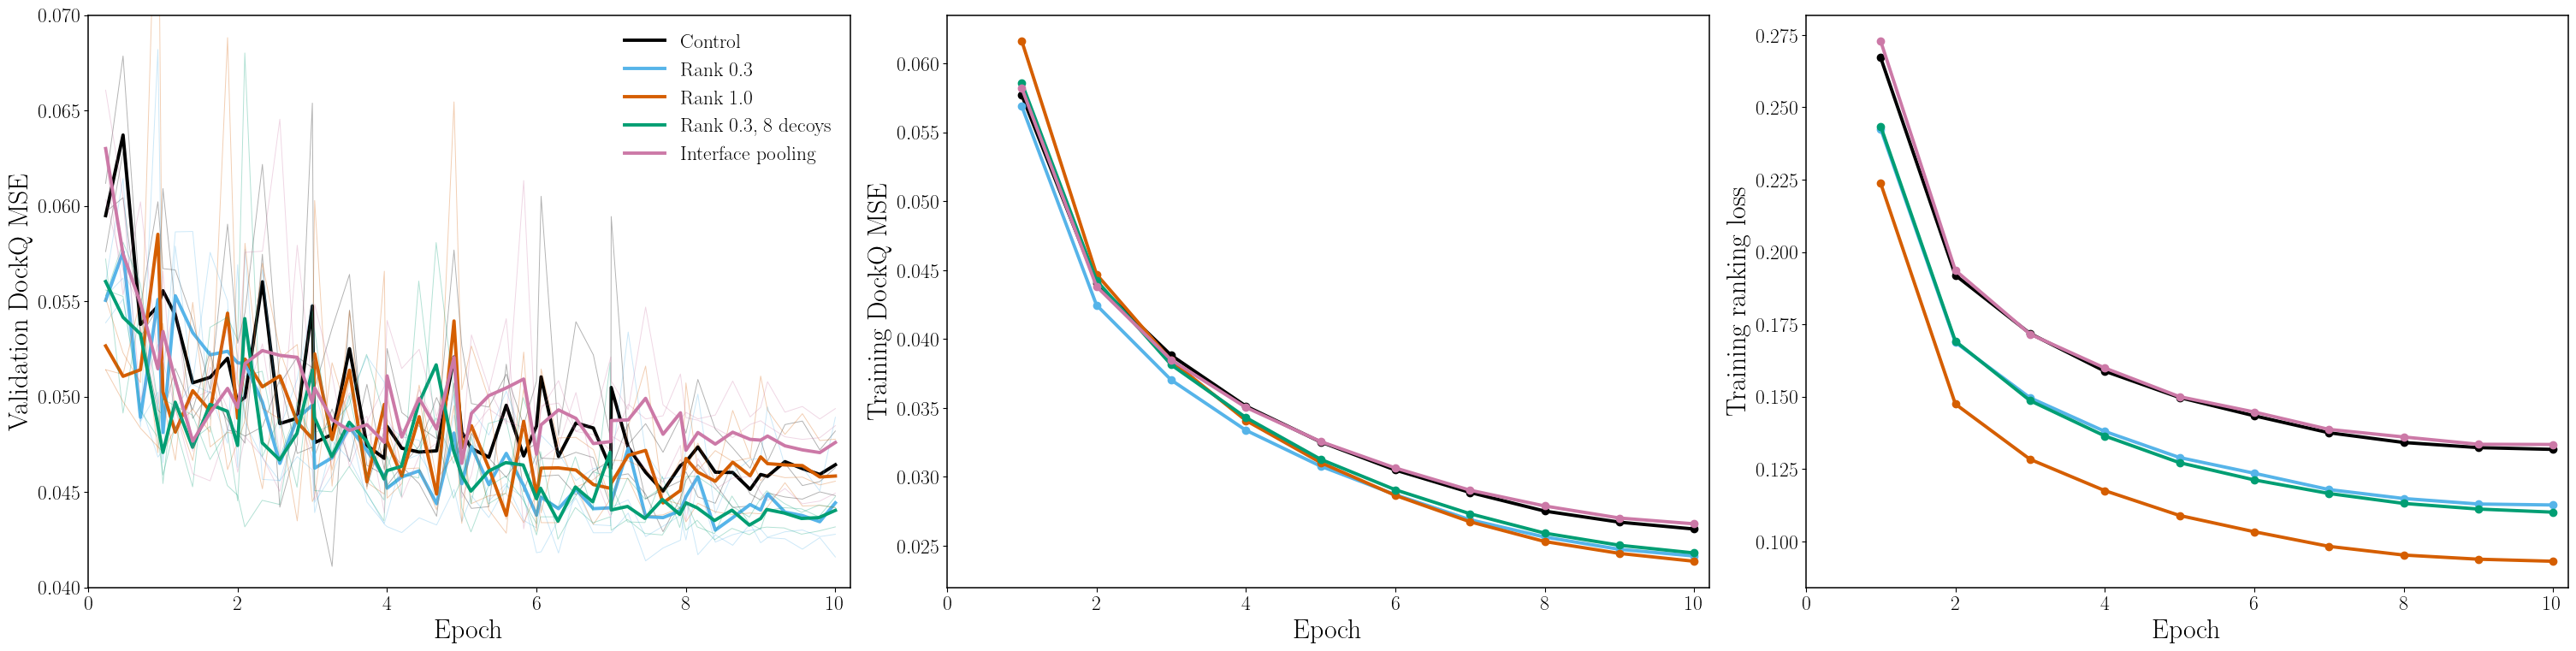

In [4]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(30, 7.5), constrained_layout=True)
for arm in ARMS:
    s = steps[steps.arm == arm]
    for seed in SEEDS:
        q = s[s.seed == seed]; a1.plot(q.epoch_float, q.val_target_mse, color=COLOR[arm], lw=.7, alpha=.3)
    m = s.groupby('global_step').agg(x=('epoch_float', 'mean'), v=('val_target_mse', 'mean'), n=('seed', 'size'))
    m = m[m.n == len(SEEDS)]; a1.plot(m.x, m.v, color=COLOR[arm], lw=2.8, label=LABEL[arm])
    h = history[history.arm == arm]
    for col, ax in (('train_target_mse', a2), ('train_rank_loss', a3)):
        g = h.groupby('epoch')[col].mean(); ax.plot(g.index, g, color=COLOR[arm], lw=2.8, marker='o', ms=6, label=LABEL[arm])
for ax, ylab in ((a1, 'Validation DockQ MSE'), (a2, 'Training DockQ MSE'), (a3, 'Training ranking loss')):
    ax.set_xlabel('Epoch'); ax.set_ylabel(ylab); ax.set_xlim(0, EPOCHS + .2)
a1.set_ylim(.04, .07); a1.legend(frameon=False, loc='upper right')
save(fig, 'learning_curves')

## Metrics at the selected checkpoint

Pooled MSE over decoys, macro (per-target mean) MSE, $\langle\rho\rangle$ = mean within-target Spearman, top-1 = mean
true DockQ of each target's top-ranked decoy, high recall/precision for true and predicted DockQ $\geq 0.80$, high
AUC = ROC AUC for true DockQ $\geq 0.80$.

In [5]:
def metrics_of(p):
    y = p.true_target.to_numpy(); f = p.predicted_target.to_numpy(); hi = y >= .8; ph = f >= .8
    per_t = p.groupby('target_id')[['graph_name', 'true_target', 'predicted_target']].apply(lambda g: pd.Series(dict(
        rho=spearmanr(g.true_target, g.predicted_target).statistic,
        top1=g.true_target.to_numpy()[np.lexsort((g.graph_name.to_numpy(), -g.predicted_target.to_numpy()))[0]],
        mse=np.mean((g.predicted_target - g.true_target) ** 2))))
    return dict(mse=np.mean((f - y) ** 2), macro_mse=per_t.mse.mean(), macro_rho=per_t.rho.mean(), top1=per_t.top1.mean(),
                high_recall=ph[hi].mean() if hi.any() else np.nan, high_precision=hi[ph].mean() if ph.any() else np.nan,
                high_bias=(f - y)[hi].mean() if hi.any() else np.nan, low_bias=(f - y)[y < .23].mean(),
                high_auc=roc_auc_score(hi, f) if 0 < hi.sum() < len(hi) else np.nan), per_t

rows, per_target = [], []
for (arm, seed), p in preds.items():
    for split in ('validation', 'test'):
        q = p[split]; _, per_t = metrics_of(q)
        per_target.append(per_t.reset_index().assign(arm=arm, seed=seed, split=split))
        for grp in (['all'] + GROUPS if split == 'test' else ['all']):
            sub = q if grp == 'all' else q[q.target_id.map(group_of) == grp]
            m, _ = metrics_of(sub)
            rows.append(dict(arm=arm, seed=seed, split=split, group=grp,
                             best_epoch=reports[arm, seed]['selected_checkpoint']['best_epoch'], **m))
metrics = pd.DataFrame(rows); per_target = pd.concat(per_target, ignore_index=True)
per_target['group'] = per_target.target_id.map(group_of)
metrics.to_csv(EXPORT / 'metrics_per_run.csv', index=False); per_target.to_csv(EXPORT / 'metrics_per_target.csv', index=False)
COLS = ['mse', 'macro_mse', 'macro_rho', 'top1', 'high_recall', 'high_precision', 'high_bias', 'low_bias', 'high_auc', 'best_epoch']
agg = metrics.groupby(['split', 'group', 'arm'])[COLS].agg(['mean', 'std'])
agg.to_csv(EXPORT / 'metrics_by_arm.csv')
rng = np.random.default_rng(0)
def boot(v, n=10_000):
    v = np.asarray(v); idx = rng.integers(0, len(v), (n, len(v)))
    return v.mean(), *np.percentile(v[idx].mean(1), [2.5, 97.5])

## Step 1: selection on validation

Seed means $\pm$ SD on the 35 validation targets, then the arm's mean rank over the three selection metrics (lower is
better). Differences from the control are paired per target (seed-mean values) with 95\% bootstrap intervals over the 35
targets; validation MSE also has seed-to-seed spreads of about 0.001.

In [6]:
val = metrics[(metrics.split == 'validation') & metrics.arm.isin(ARMS)]
sel = val.groupby('arm')[['mse', 'macro_rho', 'top1', 'high_recall', 'high_bias']].agg(['mean', 'std']).loc[ARMS]
ranks = pd.DataFrame({'mse': sel[('mse', 'mean')].rank(), 'macro_rho': (-sel[('macro_rho', 'mean')]).rank(),
                      'top1': (-sel[('top1', 'mean')]).rank()})
ranks['mean_rank'] = ranks.mean(axis=1)
CHOSEN = ranks.mean_rank.idxmin()
display(sel.round(4)); display(ranks.round(2))
display(Markdown(f'**Chosen on validation: `{CHOSEN}`** (mean rank {ranks.mean_rank.min():.2f}).'))

def paired(split, arm, base='control', group=None):
    pt = per_target[(per_target.split == split)]
    if group: pt = pt[pt.group == group]
    w = pt[pt.arm.isin([arm, base])].groupby(['arm', 'target_id'])[['rho', 'mse', 'top1']].mean().unstack(0)
    return {'drho': w[('rho', arm)] - w[('rho', base)], 'dmse': -(w[('mse', arm)] - w[('mse', base)]),
            'dtop1': w[('top1', arm)] - w[('top1', base)]}

eff = []
for arm in ARMS[1:]:
    for split, groups in (('validation', [None]), ('test', [None] + GROUPS)):
        for g in groups:
            d = paired(split, arm, group=g)
            for metric, v in d.items():
                mean, lo, hi = boot(v)
                eff.append(dict(arm=arm, split=split, group=g or 'all', metric=metric, n=len(v), mean=mean, lo=lo, hi=hi,
                                better=int((v > 0).sum())))
eff = pd.DataFrame(eff); eff.to_csv(EXPORT / 'paired_vs_control.csv', index=False)
display(Markdown('**Validation, paired vs control** (positive favours the arm; −ΔMSE is the MSE reduction):'))
display(eff[eff.split == 'validation'].set_index(['arm', 'metric'])[['mean', 'lo', 'hi', 'better', 'n']].round(4))

mse         macro_rho            top1         high_recall  \
                   mean     std      mean     std    mean     std        mean   
arm                                                                             
control          0.0435  0.0022    0.7006  0.0126  0.5911  0.0236      0.0307   
rank0.3          0.0424  0.0013    0.7057  0.0092  0.5897  0.0184      0.0917   
rank1.0          0.0432  0.0004    0.7121  0.0061  0.5862  0.0088      0.0886   
rank0.3_8decoys  0.0427  0.0002    0.7133  0.0194  0.5963  0.0221      0.0405   
interface_pool   0.0450  0.0017    0.7119  0.0013  0.5533  0.0312      0.0568   

                        high_bias          
                    std      mean     std  
arm                                        
control          0.0266   -0.3005  0.0278  
rank0.3          0.0443   -0.2725  0.0069  
rank1.0          0.0585   -0.2987  0.0308  
rank0.3_8decoys  0.0346   -0.2970  0.0145  
interface_pool   0.0541   -0.3042  0.0276

,mse,macro_rho,top1,mean_rank
arm,,,,
control,4.0,5.0,2.0,3.67
rank0.3,1.0,4.0,3.0,2.67
rank1.0,3.0,2.0,4.0,3.00
rank0.3_8decoys,2.0,1.0,1.0,1.33
interface_pool,5.0,3.0,5.0,4.33


**Chosen on validation: `rank0.3_8decoys`** (mean rank 1.33).

**Validation, paired vs control** (positive favours the arm; −ΔMSE is the MSE reduction):

mean      lo      hi  better   n
arm             metric                                    
rank0.3         drho    0.0051 -0.0281  0.0284      24  35
                dmse    0.0015 -0.0005  0.0038      19  35
                dtop1  -0.0014 -0.0487  0.0402      17  35
rank1.0         drho    0.0115 -0.0164  0.0334      25  35
                dmse    0.0006 -0.0021  0.0032      22  35
                dtop1  -0.0049 -0.0449  0.0358      14  35
rank0.3_8decoys drho    0.0127 -0.0034  0.0288      25  35
                dmse    0.0012 -0.0005  0.0030      20  35
                dtop1   0.0052 -0.0453  0.0530      16  35
interface_pool  drho    0.0113 -0.0165  0.0505       9  35
                dmse   -0.0011 -0.0043  0.0022      14  35
                dtop1  -0.0378 -0.0813  0.0009      13  35

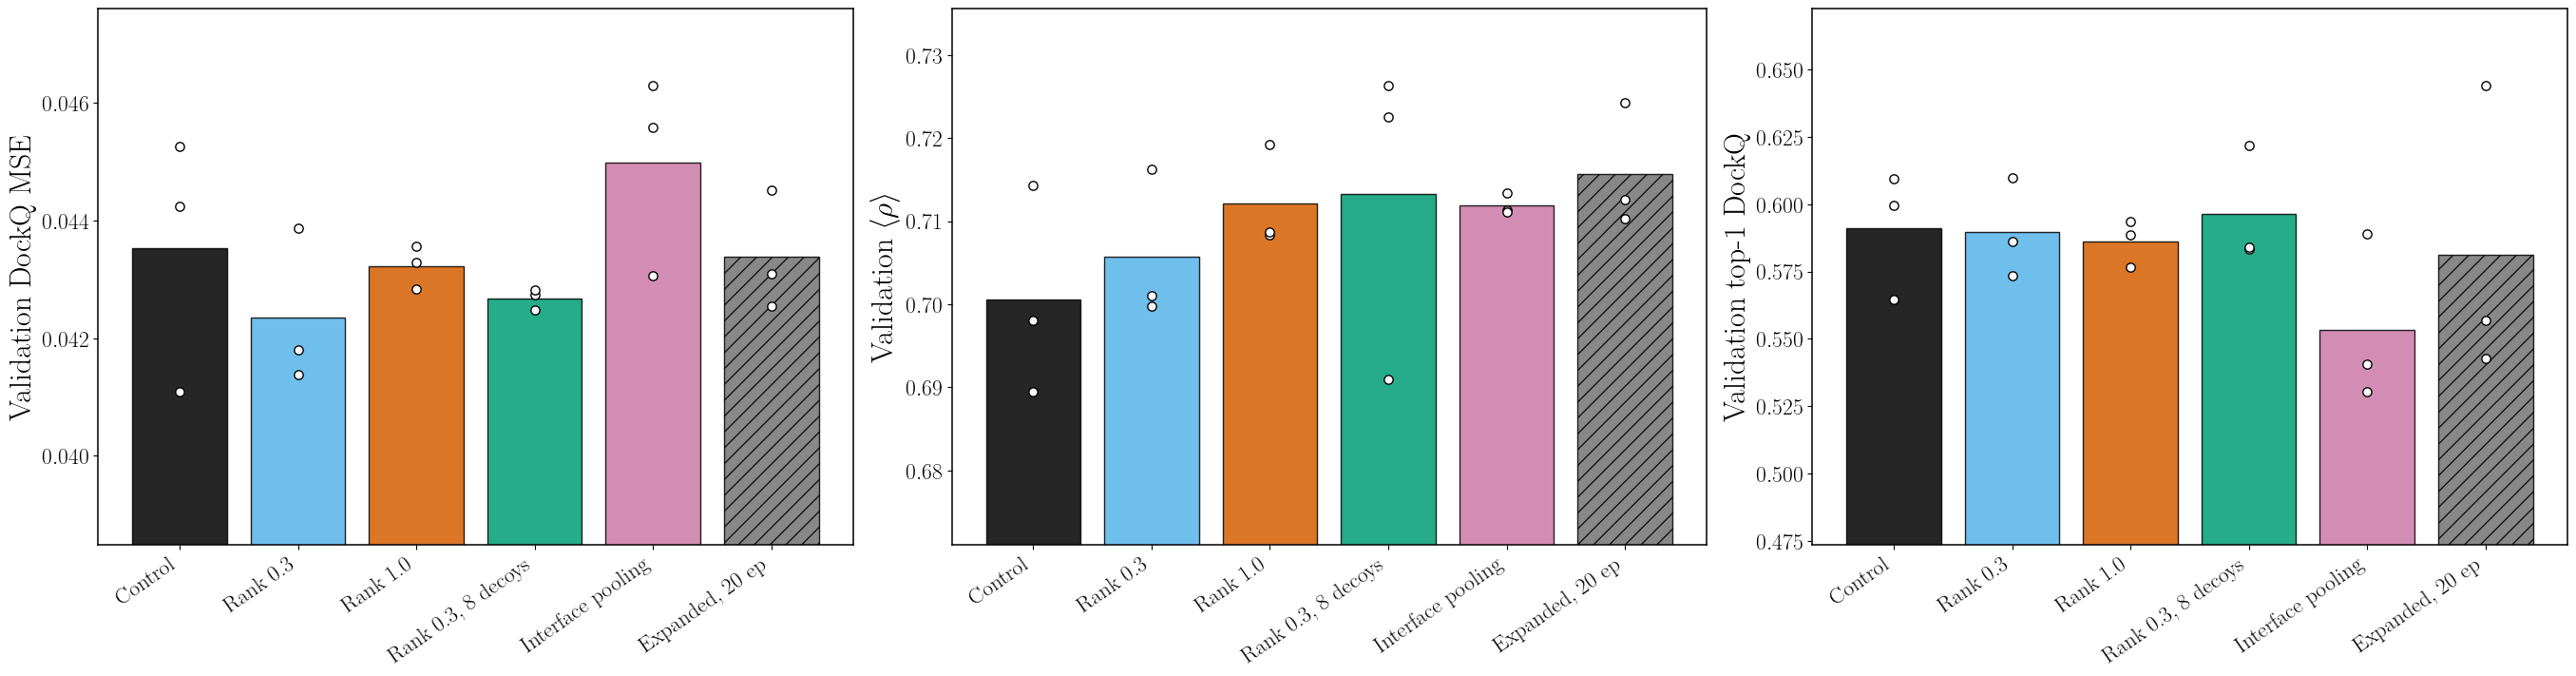

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(27, 7), constrained_layout=True)
for ax, col, ylab in zip(axes, ('mse', 'macro_rho', 'top1'), ('Validation DockQ MSE', r'Validation $\langle\rho\rangle$', 'Validation top-1 DockQ')):
    arms = ARMS + ['expanded']
    for i, arm in enumerate(arms):
        v = metrics[(metrics.split == 'validation') & (metrics.arm == arm)][col]
        ax.bar(i, v.mean(), color=COLOR[arm], alpha=.85, edgecolor='black', lw=1, hatch='' if arm in ARMS else '//')
        ax.scatter(np.full(len(v), i), v, color='white', edgecolor='black', s=45, lw=1, zorder=5)
    ax.set_xticks(range(len(arms)), [LABEL[a] for a in arms], rotation=35, ha='right')
    ax.set_ylabel(ylab)
    lo = metrics[(metrics.split == 'validation') & metrics.arm.isin(arms)][col]
    ax.set_ylim(lo.min() - (lo.max() - lo.min()) * .5, lo.max() + (lo.max() - lo.min()) * .25)
save(fig, 'validation_selection')

## Step 2: test results

Read after the choice above. Top: pooled test MSE, $\langle\rho\rangle$ and top-1 for each arm and the 20-epoch
references. Below: paired differences from the control on validation (open) and test (filled), with 95\% bootstrap
intervals; a gain that replicates should appear on both.

,mse,macro_mse,macro_rho,top1,high_recall,high_precision,high_bias,low_bias,high_auc,best_epoch
arm,,,,,,,,,,
control,0.0383,0.0390,0.7616,0.5814,0.1136,0.6611,-0.2634,0.1238,0.8856,5.0000
rank0.3,0.0375,0.0380,0.7623,0.6032,0.1780,0.6557,-0.2367,0.1173,0.8850,8.0000
rank1.0,0.0364,0.0370,0.7753,0.6265,0.1585,0.6087,-0.2541,0.0951,0.8873,6.3333
rank0.3_8decoys,0.0372,0.0376,0.7719,0.6047,0.0922,0.6626,-0.2654,0.1126,0.8854,8.0000
interface_pool,0.0372,0.0379,0.7420,0.6088,0.1289,0.6164,-0.2348,0.1289,0.8967,4.0000
expanded,0.0397,0.0401,0.7597,0.5991,0.1203,0.6617,-0.2593,0.1120,0.8788,7.6667
original_only,0.0473,0.0490,0.7066,0.5377,0.2192,0.5892,-0.2463,0.1415,0.8610,11.0000
expanded_large,0.0426,0.0428,0.7355,0.5530,0.0885,0.6932,-0.3031,0.1119,0.8683,2.6667


macro_rho                                     mse          \
group                 all     new orig_clean orig_homolog     all     new   
arm                                                                         
control            0.7616  0.7475     0.7653       0.8190  0.0383  0.0361   
rank0.3            0.7623  0.7504     0.7419       0.8581  0.0375  0.0354   
rank1.0            0.7753  0.7590     0.7673       0.8665  0.0364  0.0338   
rank0.3_8decoys    0.7719  0.7578     0.7607       0.8598  0.0372  0.0351   
interface_pool     0.7420  0.7157     0.7693       0.8088  0.0372  0.0352   
expanded           0.7597  0.7458     0.7496       0.8441  0.0397  0.0377   
original_only      0.7066  0.7124     0.7266       0.6394  0.0473  0.0440   
expanded_large     0.7355  0.7067     0.7477       0.8443  0.0426  0.0409   

                                           top1                     \
group           orig_clean orig_homolog     all     new orig_clean   
arm                                                                  
control             0.0473       0.0361  0.5814  0.5528     0.5884   
rank0.3             0.0491       0.0297  0.6032  0.5636     0.6363   
rank1.0             0.0479       0.0324  0.6265  0.5912     0.6526   
rank0.3_8decoys     0.0484       0.0301  0.6047  0.5739     0.6165   
interface_pool      0.0462       0.0336  0.6088  0.5841     0.6418   
expanded            0.0511       0.0315  0.5991  0.5717     0.6368   
original_only       0.0528       0.0603  0.5377  0.5324     0.5755   
expanded_large      0.0528       0.0342  0.5530  0.5068     0.5868   

                              
group           orig_homolog  
arm                           
control               0.7002  
rank0.3               0.7202  
rank1.0               0.7378  
rank0.3_8decoys       0.7234  
interface_pool        0.6572  
expanded              0.6507  
original_only         0.4864  
expanded_large        0.6994

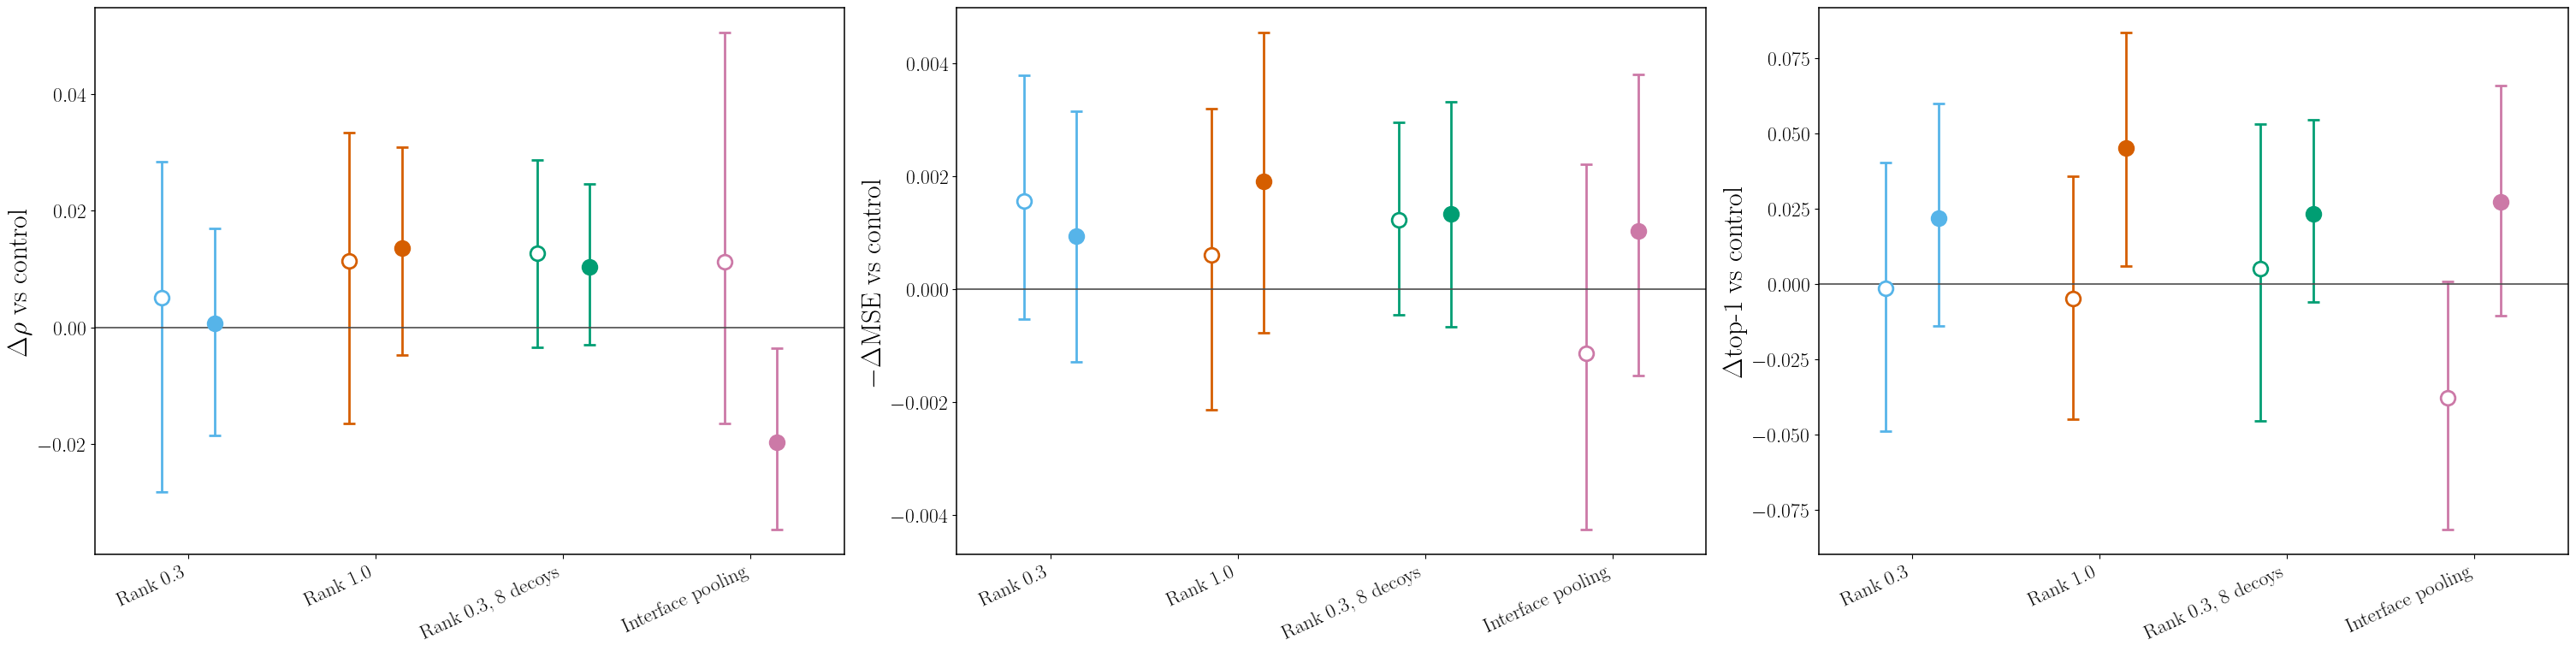

mean      lo      hi  better   n
arm             group                                           
rank0.3         all           0.0007 -0.0185  0.0170      36  61
                orig_homolog  0.0391  0.0248  0.0559       8   8
                orig_clean   -0.0234 -0.0843  0.0272       8  16
                new           0.0029 -0.0114  0.0168      20  37
rank1.0         all           0.0137 -0.0047  0.0310      40  61
                orig_homolog  0.0475  0.0326  0.0627       8   8
                orig_clean    0.0020 -0.0469  0.0445      10  16
                new           0.0114 -0.0083  0.0326      22  37
rank0.3_8decoys all           0.0104 -0.0030  0.0246      36  61
                orig_homolog  0.0408  0.0265  0.0573       8   8
                orig_clean   -0.0046 -0.0288  0.0203       8  16
                new           0.0103 -0.0075  0.0304      20  37
interface_pool  all          -0.0196 -0.0346 -0.0035      15  61
                orig_homolog -0.0102 -0.0327  0.0131       3   8
                orig_clean    0.0040 -0.0213  0.0418       4  16
                new          -0.0319 -0.0524 -0.0119       8  37

In [8]:
order = ARMS + REFS
tab = metrics[(metrics.split == 'test') & (metrics.group == 'all')].groupby('arm')[COLS].mean().loc[order]
display(tab.round(4))
by_group = metrics[metrics.split == 'test'].pivot_table(index='arm', columns='group', values=['macro_rho', 'mse', 'top1']).loc[order].round(4)
display(by_group)

fig, axes = plt.subplots(1, 3, figsize=(30, 7.5), constrained_layout=True)
for ax, metric, ylab in zip(axes, ('drho', 'dmse', 'dtop1'), (r'$\Delta\rho$ vs control', r'$-\Delta$MSE vs control', r'$\Delta$top-1 vs control')):
    for i, arm in enumerate(ARMS[1:]):
        for dx, split, face in ((-.14, 'validation', 'white'), (.14, 'test', COLOR[arm])):
            e = eff[(eff.arm == arm) & (eff.split == split) & (eff.group == 'all') & (eff.metric == metric)].iloc[0]
            ax.errorbar(i + dx, e['mean'], yerr=[[e['mean'] - e.lo], [e.hi - e['mean']]], fmt='o', ms=12, color=COLOR[arm],
                        mfc=face, mec=COLOR[arm], mew=2, capsize=5, lw=2)
    ax.axhline(0, color='0.3', lw=1.2); ax.set_xticks(range(4), [LABEL[a] for a in ARMS[1:]], rotation=25, ha='right')
    ax.set_ylabel(ylab); ax.set_xlim(-.5, 3.5)
save(fig, 'paired_vs_control')
display(eff[(eff.split == 'test') & (eff.metric == 'drho')].set_index(['arm', 'group'])[['mean', 'lo', 'hi', 'better', 'n']].round(4))

### Test by group

Test $\langle\rho\rangle$ by target group for the five arms (seed means as bars, seeds as points).

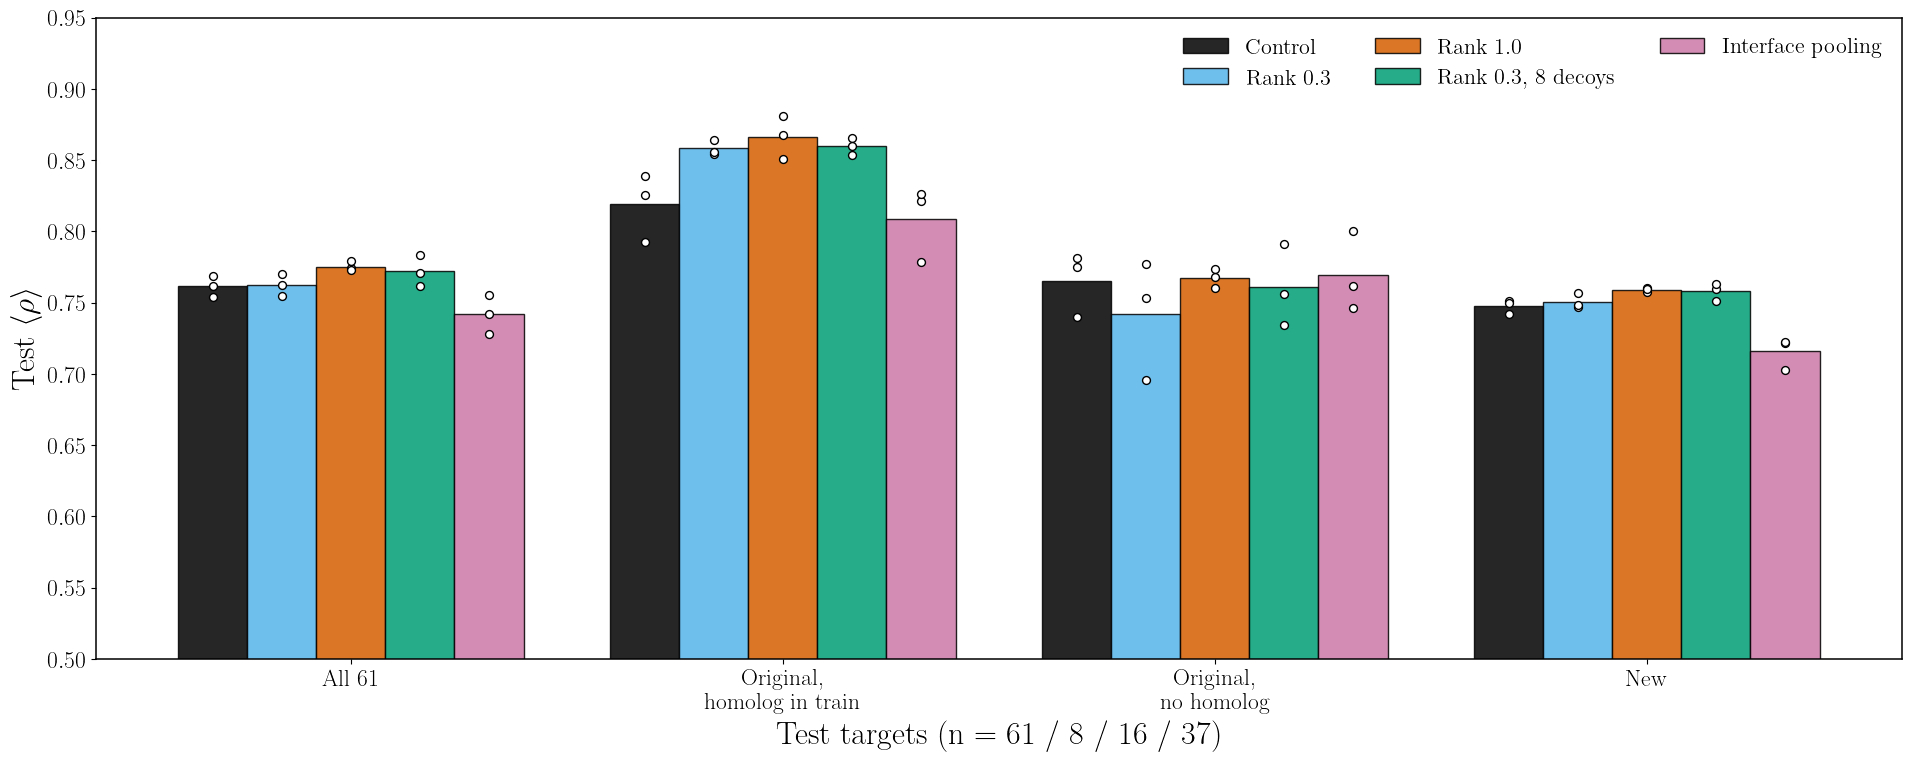

In [9]:
fig, ax = plt.subplots(figsize=(19, 7.5), constrained_layout=True)
groups = ['all'] + GROUPS; x = np.arange(len(groups)); w = .16
for k, arm in enumerate(ARMS):
    m = metrics[(metrics.split == 'test') & (metrics.arm == arm)]
    pos = x + (k - 2) * w
    ax.bar(pos, [m[m.group == g].macro_rho.mean() for g in groups], w, color=COLOR[arm], alpha=.85, edgecolor='black', lw=1, label=LABEL[arm])
    for i, g in enumerate(groups):
        v = m[m.group == g].macro_rho; ax.scatter(np.full(len(v), pos[i]), v, color='white', edgecolor='black', s=32, lw=1, zorder=5)
ax.set_xticks(x, [GROUP_LABEL[g] for g in groups]); ax.set_ylim(.5, .95)
ax.set_ylabel(r'Test $\langle\rho\rangle$'); ax.set_xlabel('Test targets (n = 61 / 8 / 16 / 37)')
ax.legend(frameon=False, loc='upper right', ncol=3, fontsize=16)
save(fig, 'test_rho_by_group')

## Does stronger ranking change where the error is?

Error decomposition on the test set: per-target offset (a whole target predicted too high or too low) and within-target
error; the median within-target slope of predicted on true DockQ; the median ratio of predicted to true spread within a
target; the number of *flat* targets (predicted SD below 25\% of the true SD).

In [10]:
rows = []
for (arm, seed), p in preds.items():
    d = p['test']; e = d.predicted_target - d.true_target
    off = d.assign(e=e).groupby('target_id').e.transform('mean')
    per = d.groupby('target_id')[['true_target', 'predicted_target']].apply(lambda g: pd.Series(dict(
        slope=np.polyfit(g.true_target, g.predicted_target, 1)[0], ratio=g.predicted_target.std() / g.true_target.std())))
    rows.append(dict(arm=arm, seed=seed, mse=np.mean(e ** 2), offset=np.mean(off ** 2), within=np.mean((e - off) ** 2),
                     within_share=np.mean((e - off) ** 2) / np.mean(e ** 2), slope=per.slope.median(), spread_ratio=per.ratio.median(),
                     flat_targets=int((per.ratio < .25).sum())))
decomp = pd.DataFrame(rows); decomp.to_csv(EXPORT / 'error_decomposition.csv', index=False)
display(decomp.groupby('arm')[['mse', 'offset', 'within', 'within_share', 'slope', 'spread_ratio', 'flat_targets']].mean().loc[ARMS + REFS].round(4))

,mse,offset,within,within_share,slope,spread_ratio,flat_targets
arm,,,,,,,
control,0.0383,0.0066,0.0318,0.8291,0.5478,0.6516,6.0000
rank0.3,0.0375,0.0070,0.0305,0.8126,0.5774,0.6715,4.6667
rank1.0,0.0364,0.0072,0.0292,0.8025,0.6016,0.6887,4.0000
rank0.3_8decoys,0.0372,0.0063,0.0309,0.8302,0.5751,0.6694,4.3333
interface_pool,0.0372,0.0066,0.0307,0.8238,0.6017,0.7068,2.6667
expanded,0.0397,0.0075,0.0322,0.8116,0.5878,0.6887,6.0000
original_only,0.0473,0.0109,0.0364,0.7698,0.5505,0.6942,6.0000
expanded_large,0.0426,0.0064,0.0361,0.8496,0.5065,0.6061,7.0000


## The interface-pooling hypothesis

The arm was added to test one idea: the whole-graph half of combined pooling encodes the interface's share of the
complex, so large complexes with small true interfaces are under-predicted as a whole and their predictions flatten. If
so, with interface-only pooling (a) the correlation between a target's offset and its interface share should weaken,
(b) prediction spread should depend less on interface share, and (c) the hard targets should recover. Left: per-target
mean prediction minus mean true DockQ against interface share (seed means). Right: predicted/true spread against interface share.

,r_offset_share,r_spread_share,r_rho_share,hard4_offset,hard4_ratio,hard4_rho,hard6_rho
arm,,,,,,,
control,0.470,0.655,0.662,-0.144,0.162,0.369,0.406
rank0.3,0.514,0.662,0.576,-0.155,0.159,0.244,0.330
rank1.0,0.445,0.600,0.568,-0.173,0.212,0.325,0.406
rank0.3_8decoys,0.413,0.594,0.567,-0.158,0.179,0.317,0.395
interface_pool,0.279,0.560,0.598,-0.108,0.279,0.441,0.486
expanded,0.533,0.657,0.604,-0.167,0.160,0.316,0.399
original_only,0.439,0.656,0.700,-0.145,0.199,0.247,0.341
expanded_large,0.584,0.646,0.589,-0.173,0.159,0.264,0.316


,Control,Rank 0.3,Rank 1.0,Rank 0.3 8 decoys,Interface pooling
target_id,,,,,
1kac,0.125,-0.259,-0.167,0.013,0.089
9wlp,0.340,0.297,0.393,0.313,0.444
4hwi,0.515,0.423,0.497,0.445,0.761
1he8,0.498,0.515,0.576,0.498,0.470
3o2s,0.552,0.482,0.564,0.528,0.651
6fg8,0.404,0.523,0.571,0.571,0.499


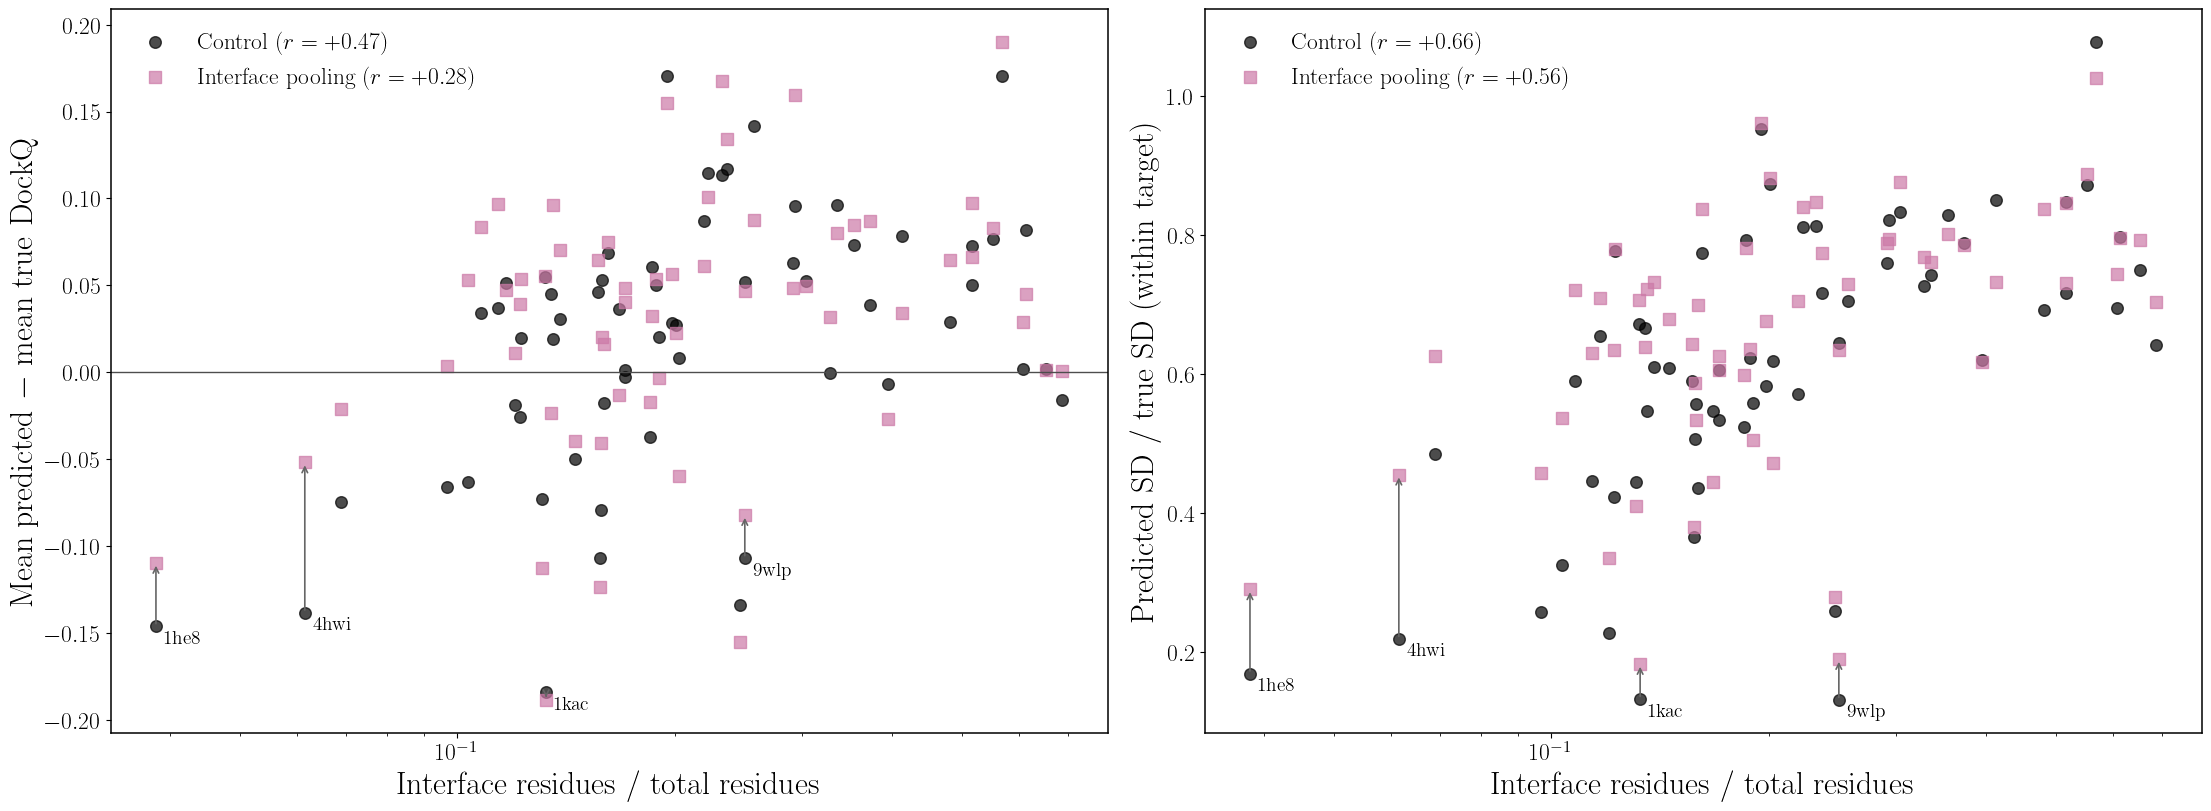

In [11]:
props = pd.read_csv(EXPANSION / 'dataset_comparison_analysis' / 'structure_properties.csv').set_index('target')
props['interface_fraction'] = props.interface_residues / props.n_residues
def target_table(arm):
    rows = []
    for seed in SEEDS:
        d = preds[arm, seed]['test']
        g = d.groupby('target_id')
        rows.append(pd.DataFrame(dict(seed=seed, offset=g.predicted_target.mean() - g.true_target.mean(),
                                      ratio=g.predicted_target.std() / g.true_target.std(),
                                      rho=g[['true_target', 'predicted_target']].apply(lambda x: spearmanr(x.true_target, x.predicted_target).statistic))))
    return pd.concat(rows).groupby(level=0)[['offset', 'ratio', 'rho']].mean().join(props[['interface_fraction', 'n_residues']])
TT = {a: target_table(a) for a in ARMS + REFS}
rows = []
for a in ARMS + REFS:
    t = TT[a]
    rows.append(dict(arm=a, r_offset_share=spearmanr(t.interface_fraction, t.offset).statistic, r_spread_share=spearmanr(t.interface_fraction, t.ratio).statistic,
                     r_rho_share=spearmanr(t.interface_fraction, t.rho).statistic, hard4_offset=t.loc[HARD[:4], 'offset'].mean(), hard4_ratio=t.loc[HARD[:4], 'ratio'].mean(),
                     hard4_rho=t.loc[HARD[:4], 'rho'].mean(), hard6_rho=t.loc[HARD, 'rho'].mean()))
hyp = pd.DataFrame(rows).set_index('arm'); hyp.to_csv(EXPORT / 'interface_hypothesis.csv'); display(hyp.round(3))
display(pd.concat({LABEL[a].replace(', ', ' '): TT[a].loc[HARD, 'rho'] for a in ARMS}, axis=1).round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(22, 8), constrained_layout=True)
for arm, mk in (('control', 'o'), ('interface_pool', 's')):
    t = TT[arm]
    a1.scatter(t.interface_fraction, t.offset, s=70, marker=mk, color=COLOR[arm], alpha=.7, label=f"{LABEL[arm]} ($r = {spearmanr(t.interface_fraction, t.offset).statistic:+.2f}$)")
    a2.scatter(t.interface_fraction, t.ratio, s=70, marker=mk, color=COLOR[arm], alpha=.7, label=f"{LABEL[arm]} ($r = {spearmanr(t.interface_fraction, t.ratio).statistic:+.2f}$)")
for t_ in HARD[:4]:
    a, b = TT['control'].loc[t_], TT['interface_pool'].loc[t_]
    a1.annotate('', xy=(b.interface_fraction, b.offset), xytext=(a.interface_fraction, a.offset), arrowprops=dict(arrowstyle='->', color='0.4', lw=1.2))
    a1.annotate(t_, (a.interface_fraction, a.offset), fontsize=14, xytext=(6, -12), textcoords='offset points')
    a2.annotate('', xy=(b.interface_fraction, b.ratio), xytext=(a.interface_fraction, a.ratio), arrowprops=dict(arrowstyle='->', color='0.4', lw=1.2))
    a2.annotate(t_, (a.interface_fraction, a.ratio), fontsize=14, xytext=(6, -12), textcoords='offset points')
a1.axhline(0, color='0.3', lw=1)
for ax in (a1, a2): ax.set_xlabel('Interface residues / total residues'); ax.set_xscale('log'); ax.legend(frameon=False, loc='upper left')
a1.set_ylabel('Mean predicted $-$ mean true DockQ'); a2.set_ylabel('Predicted SD / true SD (within target)')
save(fig, 'interface_hypothesis')

## Three-seed ensemble

Averaging the three seeds' predictions for each decoy costs nothing extra once the runs exist. Single-run values are
seed means for comparison.

In [12]:
def ensemble(arm, split):
    base = preds[arm, SEEDS[0]][split].copy()
    base['predicted_target'] = np.mean([preds[arm, s][split].predicted_target.to_numpy() for s in SEEDS], axis=0)
    return base
rows = []
for arm in ARMS + ['expanded']:
    for split in ('validation', 'test'):
        m, _ = metrics_of(ensemble(arm, split))
        single = metrics[(metrics.arm == arm) & (metrics.split == split) & (metrics.group == 'all')]
        rows.append(dict(arm=arm, split=split, mse_single=single.mse.mean(), mse_ens=m['mse'], rho_single=single.macro_rho.mean(), rho_ens=m['macro_rho'],
                         top1_single=single.top1.mean(), top1_ens=m['top1']))
ens = pd.DataFrame(rows); ens.to_csv(EXPORT / 'ensemble.csv', index=False)
display(ens.set_index(['split', 'arm']).sort_index().round(4))

mse_single  mse_ens  rho_single  rho_ens  \
split      arm                                                         
test       control              0.0383   0.0360      0.7616   0.7811   
           expanded             0.0397   0.0365      0.7597   0.7741   
           interface_pool       0.0372   0.0350      0.7420   0.7566   
           rank0.3              0.0375   0.0356      0.7623   0.7811   
           rank0.3_8decoys      0.0372   0.0353      0.7719   0.7865   
           rank1.0              0.0364   0.0342      0.7753   0.7917   
validation control              0.0435   0.0415      0.7006   0.7151   
           expanded             0.0434   0.0413      0.7157   0.7311   
           interface_pool       0.0450   0.0429      0.7119   0.7250   
           rank0.3              0.0424   0.0404      0.7057   0.7140   
           rank0.3_8decoys      0.0427   0.0409      0.7133   0.7255   
           rank1.0              0.0432   0.0412      0.7121   0.7230   

                            top1_single  top1_ens  
split      arm                                     
test       control               0.5814    0.6119  
           expanded              0.5991    0.6029  
           interface_pool        0.6088    0.5987  
           rank0.3               0.6032    0.6044  
           rank0.3_8decoys       0.6047    0.6419  
           rank1.0               0.6265    0.6406  
validation control               0.5911    0.5637  
           expanded              0.5812    0.5839  
           interface_pool        0.5533    0.5488  
           rank0.3               0.5897    0.6109  
           rank0.3_8decoys       0.5963    0.6053  
           rank1.0               0.5862    0.5733

## Against Rosetta, ZRank2 and PyDock

All test targets, every method on the same decoys. Raw-score $\rho$ as in the PRE paper (more negative is better; GATE's
predicted DockQ negated; GATE = seed mean per target), ordered best to worst, $\pm 1$ SD over targets. Rosetta caveat as in
the dataset-size notebook: relaxed models for original targets, `score_jd2` on GROMACS models for new targets.

rho          top1       
                  mean    std   mean    std
method                                     
rank1.0         -0.775  0.173  0.627  0.286
rank0.3_8decoys -0.772  0.166  0.605  0.298
rank0.3         -0.762  0.192  0.603  0.296
control         -0.762  0.157  0.581  0.303
expanded        -0.760  0.171  0.599  0.297
ZRank2          -0.746  0.133  0.593  0.296
interface_pool  -0.742  0.149  0.609  0.292
original_only   -0.707  0.195  0.538  0.306
PyDock          -0.646  0.295  0.536  0.329
Rosetta         -0.423  0.297  0.815  0.202

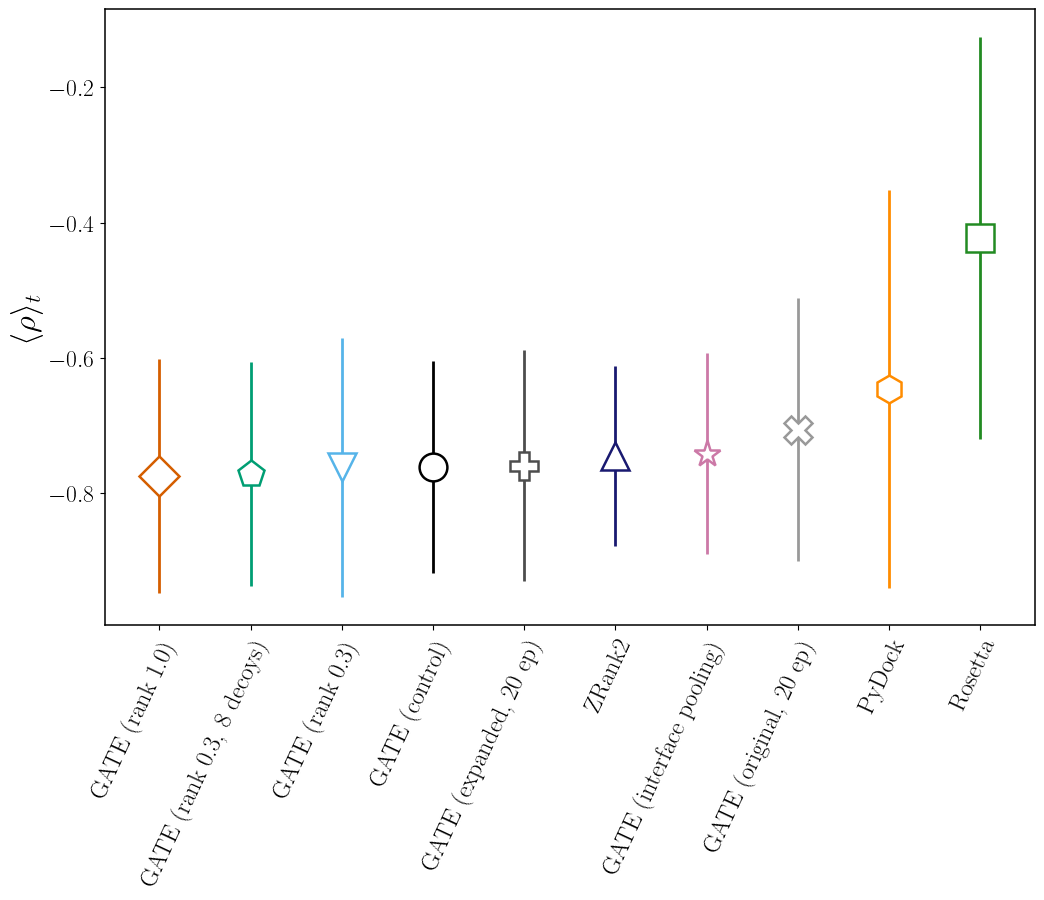

,best_outright,within_002,total
arm,,,
control,29,9,38
rank0.3,33,6,39
rank1.0,34,6,40
rank0.3_8decoys,33,6,39
interface_pool,17,9,26
expanded,28,6,34
original_only,15,11,26


In [13]:
sys.path.insert(0, str(GATE / 'ch3_comparison'))
from raw_score_parsers import PARSERS, parse_dockq, base_key
BALANCED = Path('/scratch/uniformly_sampled_ppi_data/all_supersampled_balanced_datasets 3/all_supersampled_balanced_datasets')
BM55 = Path('/scratch/ppi_scoring_data/bm_55_scoring')
NEW_SCORES = EXPANSION / 'results' / 'scores'
CLASSICAL = ['Rosetta', 'ZRank2', 'PyDock']

def score_table(t):
    if t in new_targets:
        tab = pd.concat([pd.read_csv(NEW_SCORES / f'{t}_{k}_scores.csv', index_col=0) for k in ('sampled', 'random')])
    elif (BALANCED / f'{t}_supersampled_balanced_scores.csv').exists():
        tab = pd.read_csv(BALANCED / f'{t}_supersampled_balanced_scores.csv')
    else:
        d = BM55 / f'scores_sampled_{t}'; frames = []
        files = {'ZRank': ('ZRank2', 'zrank_files_{k}_{t}.txt.zr.out'), 'Rosetta': ('Rosetta', 'rosetta_scores_{k}_{t}.txt'),
                 'PyDock': ('PyDock', 'pydock_scores_{t}_{k}.txt')}
        for kind in ('sampled', 'random'):
            dq = {base_key(n): v for n, v in parse_dockq(d / f'dockq_scores_{t}_{kind}.txt').items()}
            cols = {c: {base_key(n): v for n, v in PARSERS[p](d / f.format(k=kind, t=t)).items()} for c, (p, f) in files.items()}
            frames.append(pd.DataFrame({'Decoy': list(dq), 'DockQ': list(dq.values()), **{c: [cols[c].get(n, np.nan) for n in dq] for c in files}}))
        tab = pd.concat(frames, ignore_index=True)
    tab = tab.rename(columns={'Decoy': 'decoy', 'ZRank': 'ZRank2'})[['decoy', 'DockQ'] + CLASSICAL]
    conflicting = tab.groupby('decoy').nunique(dropna=False).max(axis=1) > 1
    return tab[~tab.decoy.isin(conflicting[conflicting].index)].drop_duplicates('decoy')

def top1(y, s, names):
    return y[np.lexsort((names, -s))[0]]
rows = []
GATE_METHODS = ARMS + ['expanded', 'original_only']
for t in sorted(ref['test'].target_id.unique()):
    ours = ref['test'][ref['test'].target_id == t][['graph_name', 'true_target']]
    j = ours.merge(score_table(t), left_on='graph_name', right_on='decoy', how='left')
    if j.DockQ.isna().any() or j[CLASSICAL].isna().any().any() or (j.DockQ - j.true_target).abs().max() > 1e-3:
        raise ValueError(f'{t}: incomplete or mismatched score table')
    y, names = j.true_target.to_numpy(), j.graph_name.to_numpy()
    for m in CLASSICAL:
        s = -j[m].to_numpy()
        rows.append(dict(target=t, group=group_of(t), method=m, rho=spearmanr(j[m], y).statistic, top1=top1(y, s, names)))
    for a in GATE_METHODS:
        r_, t_ = [], []
        for seed in SEEDS:
            p = preds[a, seed]['test']; p = p[p.target_id == t].set_index('graph_name').loc[names, 'predicted_target'].to_numpy()
            r_.append(-spearmanr(p, y).statistic); t_.append(top1(y, p, names))
        rows.append(dict(target=t, group=group_of(t), method=a, rho=np.mean(r_), top1=np.mean(t_)))
sf = pd.DataFrame(rows); sf.to_csv(EXPORT / 'scoring_functions_per_target.csv', index=False)
summary = sf.groupby('method')[['rho', 'top1']].agg(['mean', 'std']); order = summary[('rho', 'mean')].sort_values().index.tolist()
display(summary.loc[order].round(3))
F7 = {'ZRank2': ('^', '#191970', 'ZRank2'), 'PyDock': ('h', '#FF8C00', 'PyDock'), 'Rosetta': ('s', '#228B22', 'Rosetta'),
      'original_only': ('X', '0.6', 'GATE (original, 20 ep)'), 'expanded': ('P', '0.3', 'GATE (expanded, 20 ep)')}
MK = {'control': 'o', 'rank0.3': 'v', 'rank1.0': 'D', 'rank0.3_8decoys': 'p', 'interface_pool': '*'}
for a in ARMS: F7[a] = (MK[a], COLOR[a], f'GATE ({LABEL[a].lower()})')
fig, ax = plt.subplots(figsize=(12, 8))
for i, m in enumerate(order):
    mk, c, _ = F7[m]; mu, sd = summary.loc[m, ('rho', 'mean')], summary.loc[m, ('rho', 'std')]
    ax.vlines(i, mu - sd, mu + sd, color=c, lw=2); ax.plot(i, mu, marker=mk, ms=20, mfc='white', mec=c, mew=1.8, ls='none', zorder=5)
ax.set_xticks(range(len(order)), [F7[m][2] for m in order], rotation=65, ha='right', rotation_mode='anchor', fontsize=18)
ax.set_xlim(-.6, len(order) - .4); ax.set_ylabel(r'$\langle \rho \rangle_t$', fontsize=24)
save(fig, 'fig7a_style_average_rho')

w = sf.pivot_table(index='target', columns='method', values='rho'); best = w[CLASSICAL].min(axis=1)
rows = []
for a in GATE_METHODS:
    rows.append(dict(arm=a, best_outright=int((w[a] < best).sum()), within_002=int(((w[a] >= best) & (w[a] <= best + .02)).sum()),
                     total=int((w[a] <= best + .02).sum())))
wins = pd.DataFrame(rows).set_index('arm'); wins.to_csv(EXPORT / 'targets_best_or_close.csv'); display(wins)

## Hard targets: the chosen arm against ZRank2, PyDock and Rosetta

In the style of Fig. 4 of the PRE paper: raw-score $\rho$ (more negative is better; GATE's predicted DockQ negated, seed mean per
target), every method on the same decoys. Targets are ordered left to right by increasing $\langle\rho\rangle$ of the
three classical functions (black line; vertical lines = SD over the three), so **targets get harder to the right**;
the shaded region is the hardest quartile. The five targets where GATE is worst are named.

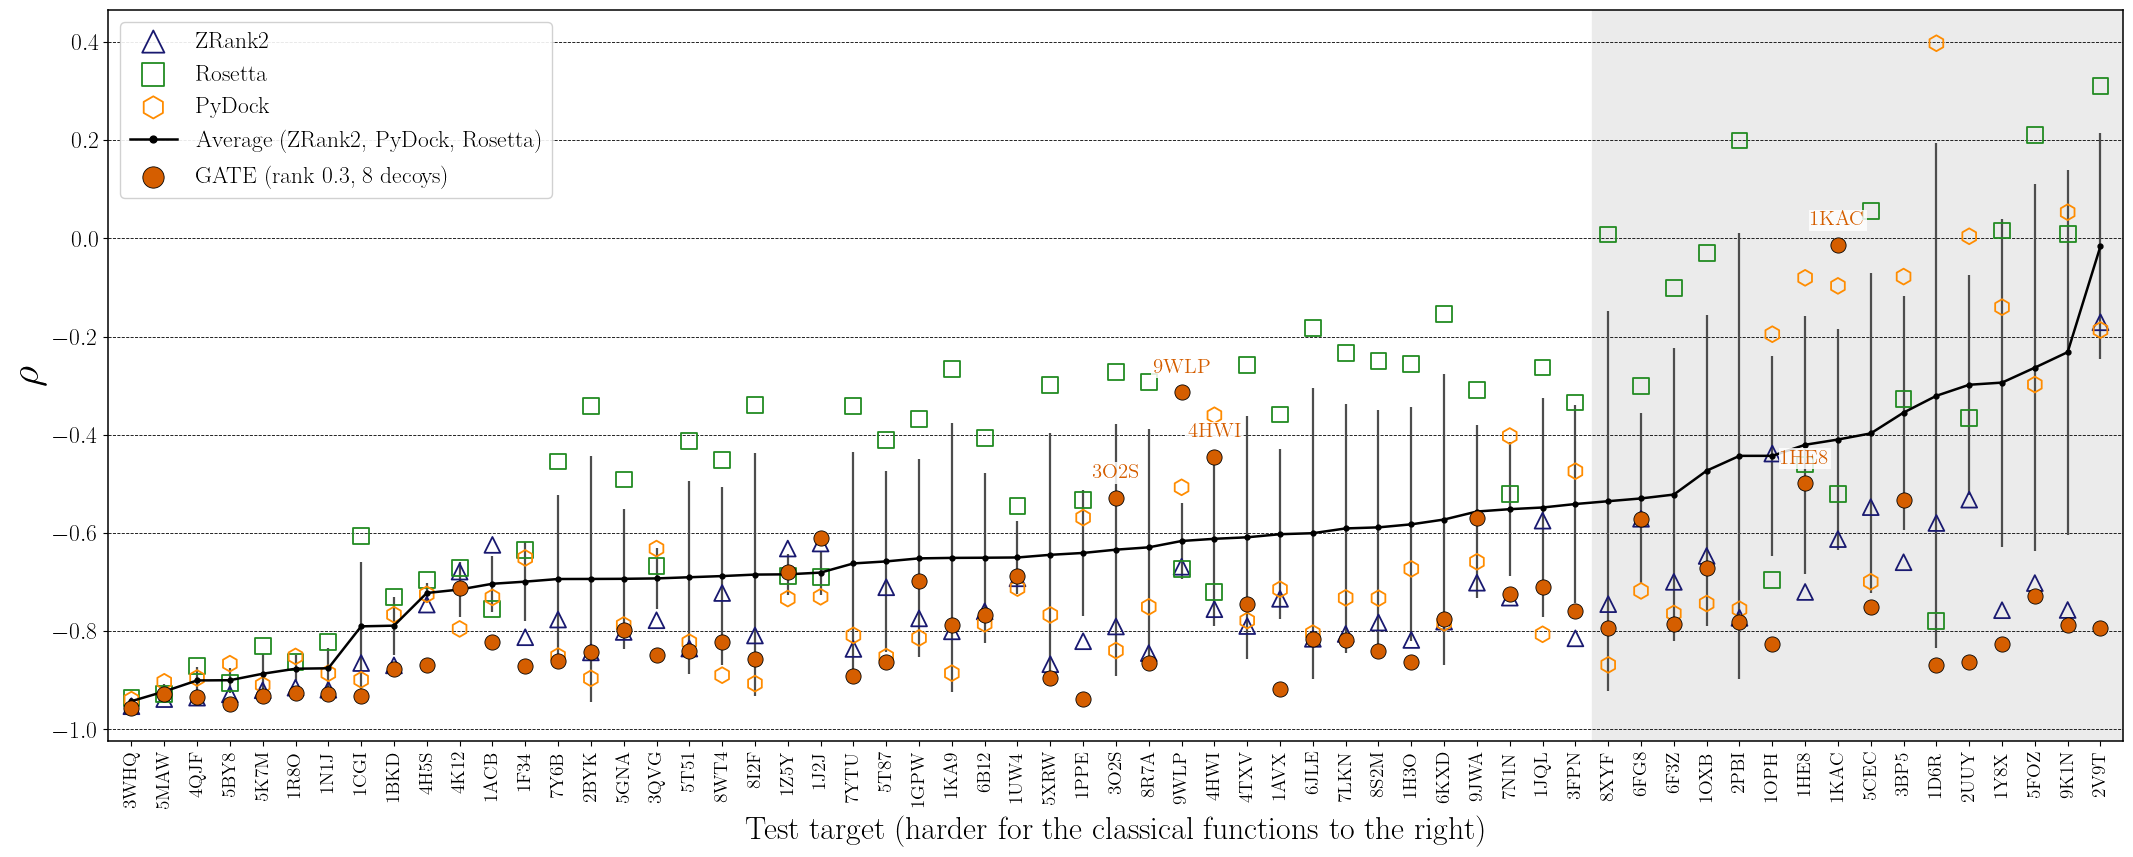

**Hardest quartile (16 targets, classical average):** mean $\rho$

,hardest quartile,other targets
method,,
rank0.3_8decoys,-0.693,-0.800
Rosetta,-0.173,-0.512
ZRank2,-0.619,-0.791
PyDock,-0.323,-0.762


In [14]:
W4 = sf.pivot_table(index='target', columns='method', values='rho')
W4['avg'] = W4[CLASSICAL].mean(axis=1); W4['sd'] = W4[CLASSICAL].std(axis=1, ddof=0)
W4 = W4.sort_values('avg'); x4 = np.arange(1, len(W4) + 1)
W4.assign(order=x4, group=W4.index.map(group_of)).to_csv(EXPORT / 'fig4_style_chosen_vs_classical.csv')
F4 = {'ZRank2': ('^', '#191970'), 'Rosetta': ('s', '#228B22'), 'PyDock': ('h', '#FF8C00')}
fig, ax = plt.subplots(figsize=(26, 9.5))
n_hard = int(np.ceil(len(W4) / 4))
ax.axvspan(len(W4) - n_hard + .5, len(W4) + .7, color='0.92', zorder=0)
for m, (mk, c) in F4.items():
    ax.scatter(x4, W4[m], marker=mk, s=130, facecolors='none', edgecolors=c, lw=1.3, label=m, zorder=3)
ax.vlines(x4, W4.avg - W4.sd, W4.avg + W4.sd, color='0.3', lw=1.6, zorder=2)
ax.plot(x4, W4.avg, color='black', marker='.', ms=7, lw=1.8, label='Average (ZRank2, PyDock, Rosetta)', zorder=5)
ax.scatter(x4, W4[CHOSEN], s=120, color='#D55E00', edgecolors='black', lw=.6, label=f'GATE ({LABEL[CHOSEN].lower()})', zorder=6)
for t in W4[CHOSEN].sort_values(ascending=False).index[:5]:
    i = W4.index.get_loc(t); ax.annotate(t.upper(), (x4[i], W4.loc[t, CHOSEN]), xytext=(0, 14), textcoords='offset points', ha='center', fontsize=15, color='#D55E00', zorder=8,
                                                bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=1))
ax.yaxis.grid(True, ls='--', lw=.6, color='black'); ax.set_axisbelow(True)
ax.set_xlim(.3, len(W4) + .7); ax.set_xticks(x4, [t.upper() for t in W4.index], rotation=90, fontsize=14)
ax.set_xlabel('Test target (harder for the classical functions to the right)'); ax.set_ylabel(r'$\rho$', fontsize=30)
ax.legend(loc='upper left', fontsize=17, markerscale=1.4, frameon=True, framealpha=.9)
save(fig, 'fig4_style_chosen_vs_classical')
hard = W4.index[-n_hard:]
display(Markdown(f'**Hardest quartile ({n_hard} targets, classical average):** mean $\\rho$'))
display(W4.loc[hard, [CHOSEN] + CLASSICAL].mean().round(3).to_frame('hardest quartile').join(W4.drop(hard)[[CHOSEN] + CLASSICAL].mean().round(3).rename('other targets')))

## Head-to-head: GATE vs ZRank2

ZRank2 is the strongest classical function on within-target ranking, so this is the comparison that matters. GATE is the chosen arm (rank 0.3, 8 decoys, seed mean per target unless stated), every target scored on the same decoys, raw-score $\rho$ as in the PRE paper (more negative is better). $\Delta\rho = \rho_{\mathrm{ZRank2}} - \rho_{\mathrm{GATE}}$, so **positive favours GATE**. Intervals are 95\% paired bootstraps over targets; $p$ is a two-sided Wilcoxon signed-rank test; a target counts as a win only with a margin above 0.02, and the sign test uses those wins and losses. The *clean* rows drop the 8 test targets whose homologs GATE saw in training.

In [15]:
from scipy.stats import wilcoxon, binomtest
Z = sf[sf.method.isin([CHOSEN, 'ZRank2'])].pivot_table(index='target', columns='method', values=['rho', 'top1'])
hh = pd.DataFrame({'zrank': Z[('rho', 'ZRank2')], 'gate': Z[('rho', CHOSEN)], 'top1_z': Z[('top1', 'ZRank2')], 'top1_g': Z[('top1', CHOSEN)]})
hh['group'] = hh.index.map(group_of); hh['d'] = hh.zrank - hh.gate
def ensemble_rho(split):
    b = preds[CHOSEN, SEEDS[0]][split][['target_id', 'graph_name', 'true_target']].copy()
    b['p'] = np.mean([preds[CHOSEN, s][split].predicted_target.to_numpy() for s in SEEDS], axis=0)
    return b.groupby('target_id')[['p', 'true_target']].apply(lambda g: -spearmanr(g.p, g.true_target).statistic)
hh['ens'] = ensemble_rho('test'); hh['d_ens'] = hh.zrank - hh.ens
hh.to_csv(EXPORT / 'head_to_head_zrank2.csv')
def line(label, sub, col='d', gate='gate', top=True):
    mean, lo, hi = boot(sub[col]); p = wilcoxon(sub[col]).pvalue
    w_, l_ = int((sub[col] > .02).sum()), int((sub[col] < -.02).sum())
    r = dict(comparison=label, n=len(sub), gate_rho=sub[gate].mean(), zrank2_rho=sub.zrank.mean(), delta=mean, median_delta=sub[col].median(), lo=lo, hi=hi, p=p,
             gate_wins=w_, ties=int((sub[col].abs() <= .02).sum()), zrank2_wins=l_, sign_p=binomtest(w_, w_ + l_).pvalue if w_ + l_ else np.nan)
    if top:
        m2, l2, h2 = boot(sub.top1_g - sub.top1_z)
        r.update(gate_top1=sub.top1_g.mean(), zrank2_top1=sub.top1_z.mean(), delta_top1=m2, top1_lo=l2, top1_hi=h2)
    return r
clean = hh[hh.group != 'orig_homolog']
rows = [line('All 61 test targets', hh), line('Clean (no homolog)', clean), line('New targets', hh[hh.group == 'new']),
        line('Original, no homolog', hh[hh.group == 'orig_clean']), line('Original, homolog in train', hh[hh.group == 'orig_homolog']),
        line('All 61, 3-seed ensemble', hh, col='d_ens', gate='ens', top=False), line('Clean, 3-seed ensemble', clean, col='d_ens', gate='ens', top=False)]
# by how hard the target is for ZRank2
q = pd.qcut(hh.zrank, 4, labels=['easiest', 'easier', 'harder', 'hardest'])
for lab in ['easiest', 'easier', 'harder', 'hardest']:
    rows.append(line(f'ZRank2 quartile: {lab}', hh[q == lab]))
# each seed on its own, and validation
for s in SEEDS:
    t = per_target[(per_target.split == 'test') & (per_target.arm == CHOSEN) & (per_target.seed == s)].set_index('target_id').rho
    x = hh.assign(gate=-t, d=hh.zrank + t); rows.append(line(f'All 61, seed {s}', x, top=False))
vr = []
for t, g in preds[CHOSEN, SEEDS[0]]['validation'].groupby('target_id'):
    tab = score_table(t)
    j = g.merge(tab, left_on='graph_name', right_on='decoy', how='left')
    if j.ZRank2.isna().mean() > .1: continue
    keep = j.ZRank2.notna().to_numpy(); yv = j.true_target.to_numpy()[keep]; names_v = j.graph_name.to_numpy()[keep]
    gv, g1 = [], []
    for s in SEEDS:
        pv = preds[CHOSEN, s]['validation']; pv = pv[pv.target_id == t].set_index('graph_name').loc[names_v, 'predicted_target'].to_numpy()
        gv.append(-spearmanr(pv, yv).statistic); g1.append(top1(yv, pv, names_v))
    zv = j.ZRank2.to_numpy()[keep]
    vr.append(dict(target=t, zrank=spearmanr(zv, yv).statistic, gate=np.mean(gv), top1_z=top1(yv, -zv, names_v), top1_g=np.mean(g1)))
vr = pd.DataFrame(vr).set_index('target'); vr['d'] = vr.zrank - vr.gate; vr.to_csv(EXPORT / 'head_to_head_zrank2_validation.csv')
rows.append(line('Validation (used to choose the arm)', vr))
H2H = pd.DataFrame(rows).set_index('comparison'); H2H.to_csv(EXPORT / 'head_to_head_zrank2_summary.csv'); display(H2H.round(3))
display(Markdown('**ZRank2 wins by the most on:**')); display(hh.sort_values('d').head(8)[['group', 'gate', 'zrank', 'd']].round(3))
display(Markdown('**GATE wins by the most on:**')); display(hh.sort_values('d', ascending=False).head(8)[['group', 'gate', 'zrank', 'd']].round(3))

,n,gate_rho,zrank2_rho,delta,median_delta,lo,hi,p,gate_wins,ties,zrank2_wins,sign_p,gate_top1,zrank2_top1,delta_top1,top1_lo,top1_hi
comparison,,,,,,,,,,,,,,,,,
All 61 test targets,61,-0.772,-0.746,0.026,0.019,-0.017,0.067,0.007,30,21,10,0.002,0.605,0.593,0.012,-0.059,0.082
Clean (no homolog),53,-0.759,-0.759,-0.000,0.009,-0.044,0.042,0.101,22,21,10,0.050,0.587,0.624,-0.038,-0.107,0.028
New targets,37,-0.758,-0.733,0.025,0.021,-0.018,0.072,0.044,19,12,6,0.015,0.574,0.595,-0.021,-0.113,0.063
"Original, no homolog",16,-0.761,-0.818,-0.057,0.006,-0.151,0.014,1.000,3,9,4,1.000,0.617,0.692,-0.075,-0.165,-0.002
"Original, homolog in train",8,-0.860,-0.659,0.201,0.191,0.119,0.283,0.008,8,0,0,0.008,0.723,0.383,0.341,0.163,0.531
"All 61, 3-seed ensemble",61,-0.787,-0.746,0.041,0.026,-0.000,0.082,0.000,33,19,9,0.000,NaN,NaN,NaN,NaN,NaN
"Clean, 3-seed ensemble",53,-0.774,-0.759,0.015,0.018,-0.027,0.055,0.007,25,19,9,0.009,NaN,NaN,NaN,NaN,NaN
ZRank2 quartile: easiest,16,-0.906,-0.882,0.024,0.012,0.010,0.041,0.001,6,10,0,0.031,0.865,0.822,0.043,-0.001,0.099
ZRank2 quartile: easier,15,-0.785,-0.793,-0.008,0.001,-0.053,0.028,0.804,5,6,4,1.000,0.677,0.704,-0.027,-0.100,0.042


**ZRank2 wins by the most on:**

,group,gate,zrank,d
target,,,,
1kac,orig_clean,-0.013,-0.612,-0.599
9wlp,new,-0.313,-0.669,-0.356
4hwi,orig_clean,-0.445,-0.755,-0.310
3o2s,new,-0.528,-0.790,-0.262
1he8,orig_clean,-0.498,-0.720,-0.222
9jwa,new,-0.570,-0.701,-0.131
3bp5,new,-0.532,-0.659,-0.127
1gpw,new,-0.699,-0.774,-0.075


**GATE wins by the most on:**

,group,gate,zrank,d
target,,,,
2v9t,new,-0.793,-0.171,0.622
1oph,orig_homolog,-0.826,-0.438,0.388
2uuy,orig_homolog,-0.863,-0.532,0.331
1d6r,orig_homolog,-0.868,-0.580,0.288
5cec,new,-0.750,-0.547,0.203
1acb,orig_homolog,-0.822,-0.624,0.198
1avx,orig_homolog,-0.918,-0.734,0.184
5t87,new,-0.864,-0.710,0.153


Left: each test target, GATE $\rho$ against ZRank2 $\rho$; points below the diagonal favour GATE. Right: the same difference for every target, sorted, coloured by group; bars above zero favour GATE.

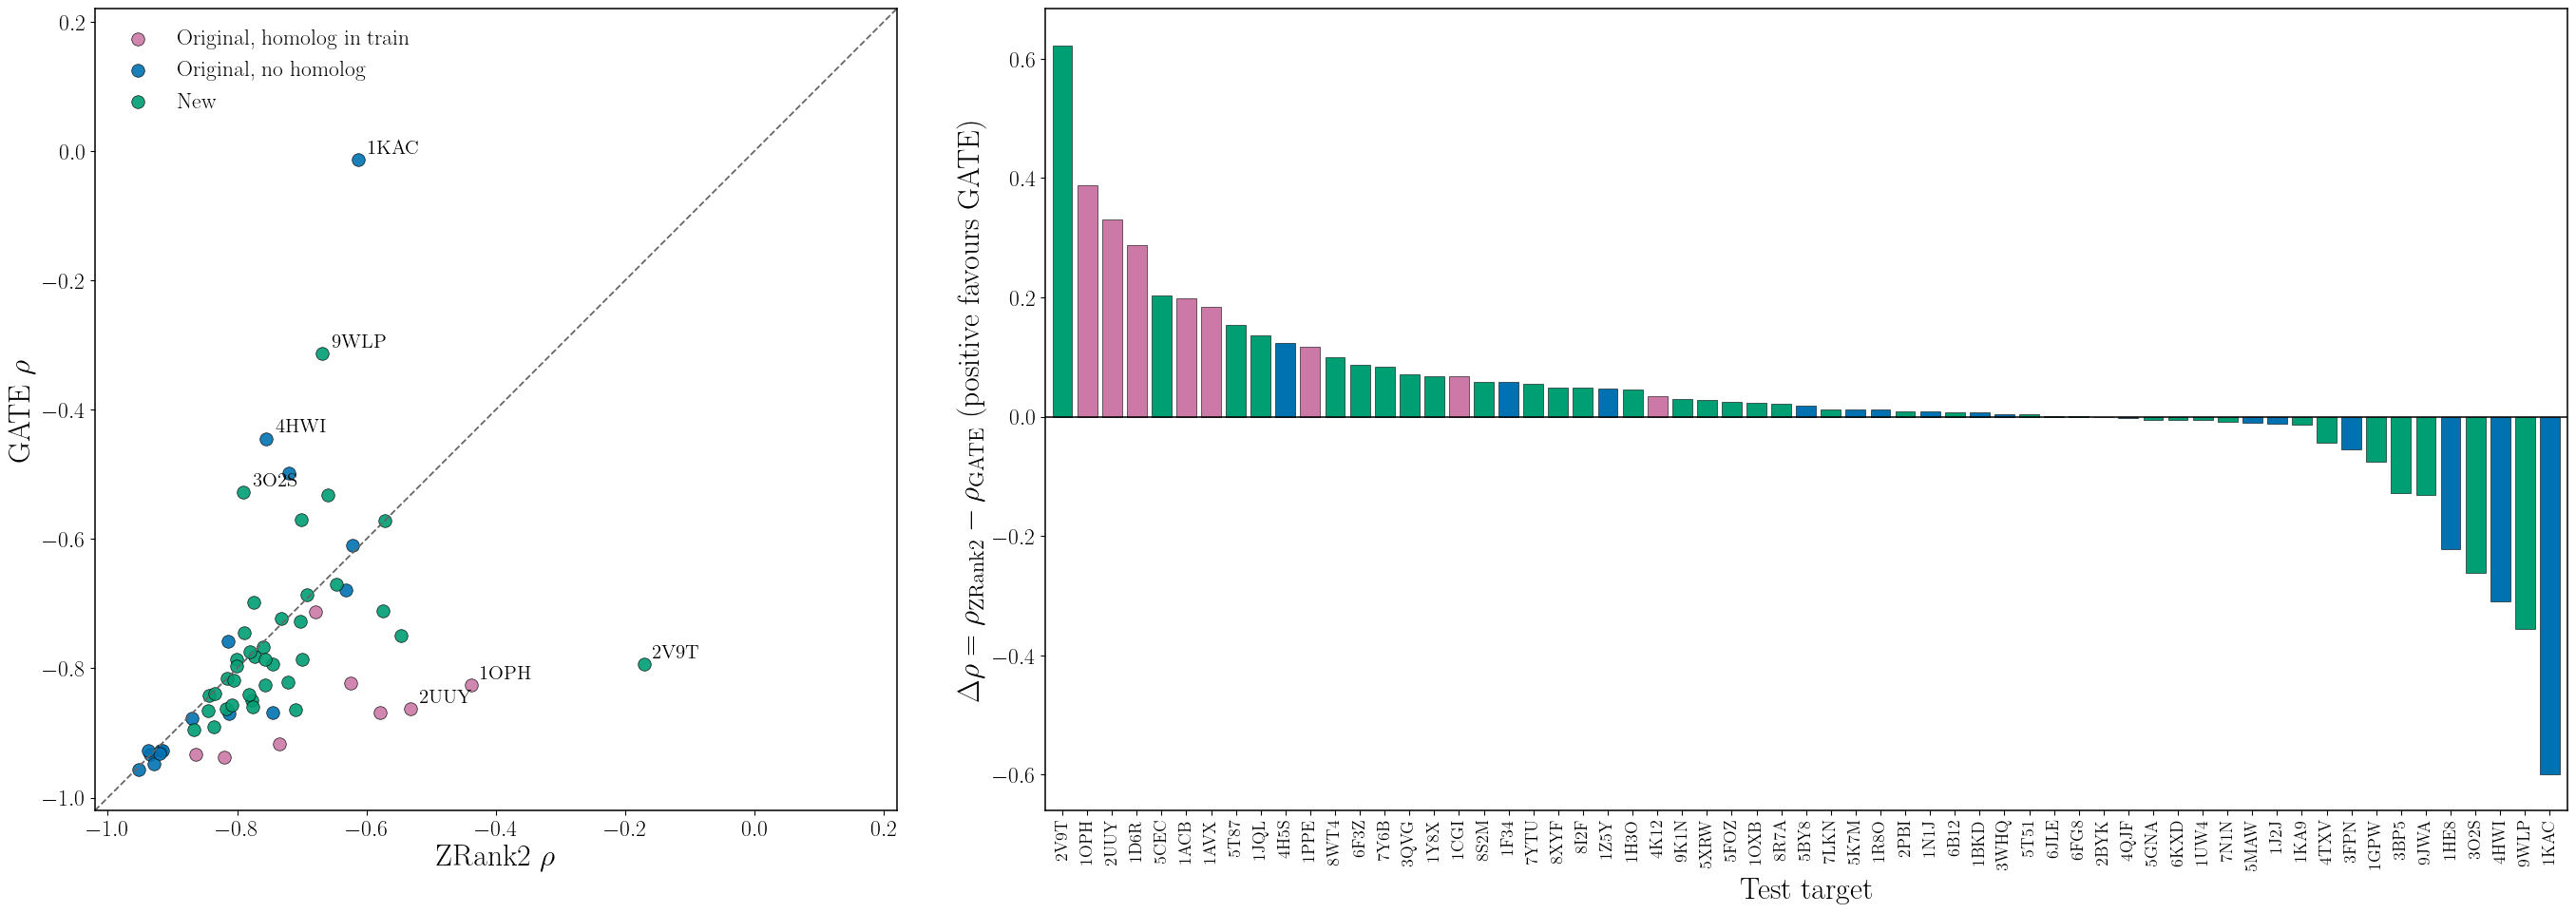

In [16]:
GC = {'orig_homolog': '#CC79A7', 'orig_clean': '#0072B2', 'new': '#009E73'}; GN = {'orig_homolog': 'Original, homolog in train', 'orig_clean': 'Original, no homolog', 'new': 'New'}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(27, 9.5), gridspec_kw=dict(width_ratios=[1, 1.75]), constrained_layout=True)
lim = (-1.02, .22)
a1.plot(lim, lim, color='0.4', ls='--', lw=1.3)
for g, c in GC.items():
    q_ = hh[hh.group == g]; a1.scatter(q_.zrank, q_.gate, s=95, color=c, edgecolors='black', lw=.5, alpha=.9, label=GN[g])
for t in list(hh.sort_values('d').index[:4]) + list(hh.sort_values('d').index[-3:]):
    a1.annotate(t.upper(), (hh.loc[t, 'zrank'], hh.loc[t, 'gate']), xytext=(7, 5), textcoords='offset points', fontsize=15)
a1.set(xlim=lim, ylim=lim); a1.set_aspect('equal', adjustable='box'); a1.set_xlabel(r'ZRank2 $\rho$'); a1.set_ylabel(r'GATE $\rho$'); a1.legend(frameon=False, loc='upper left')
s_ = hh.sort_values('d', ascending=False); xs = np.arange(len(s_))
a2.bar(xs, s_.d, color=[GC[g] for g in s_.group], edgecolor='black', lw=.4)
a2.axhline(0, color='black', lw=1.1); a2.set_xlim(-.7, len(s_) - .3); a2.set_xticks(xs, [t.upper() for t in s_.index], rotation=90, fontsize=13)
a2.set_xlabel('Test target'); a2.set_ylabel(r'$\Delta\rho = \rho_{\mathrm{ZRank2}} - \rho_{\mathrm{GATE}}$ (positive favours GATE)')
save(fig, 'head_to_head_zrank2')

## Worst-target scorecard

The question to ask of every run: **which test target is worst, and did a change help it without hurting the others?**
Worst, 10th-percentile and bottom-5 mean $\rho$ per method (sign flipped so higher is better; GATE = seed mean per
target), and for each arm how many targets moved by more than 0.02 relative to the control, plus the largest loss.

In [17]:
BETTER = -sf.pivot_table(index='target', columns='method', values='rho')
order_sc = ['rank0.3_8decoys', 'rank1.0', 'rank0.3', 'control', 'interface_pool', 'expanded', 'original_only', 'ZRank2', 'PyDock', 'Rosetta']
rows = []
for m in order_sc:
    v = BETTER[m].sort_values()
    d = BETTER[m] - BETTER['control']
    rows.append(dict(method=m, worst_target=v.index[0], worst_rho=v.iloc[0], bottom5_mean=v.iloc[:5].mean(), p10=v.quantile(.1), mean=v.mean(),
                     helped=int((d > .02).sum()), harmed=int((d < -.02).sum()), largest_loss=d.min()))
card = pd.DataFrame(rows).set_index('method'); card.to_csv(EXPORT / 'worst_target_scorecard.csv'); display(card.round(3))
worst5 = BETTER[CHOSEN].sort_values().index[:6]
display(Markdown('**The worst targets of the chosen arm**, $\\rho$ by method and by seed:'))
seedw = per_target[(per_target.split == 'test') & (per_target.arm == CHOSEN)].pivot_table(index='target_id', columns='seed', values='rho')
display(BETTER.loc[worst5, [CHOSEN, 'control', 'rank1.0', 'interface_pool', 'ZRank2', 'PyDock', 'Rosetta']].join(seedw.add_prefix('seed ')).round(3))

,worst_target,worst_rho,bottom5_mean,p10,mean,helped,harmed,largest_loss
method,,,,,,,,
rank0.3_8decoys,1kac,0.013,0.359,0.570,0.772,22,12,-0.138
rank1.0,1kac,-0.167,0.371,0.576,0.775,26,9,-0.292
rank0.3,1kac,-0.259,0.292,0.584,0.762,19,11,-0.384
control,1kac,0.125,0.371,0.552,0.762,0,0,0.000
interface_pool,1kac,0.089,0.389,0.577,0.742,10,31,-0.248
expanded,1kac,-0.116,0.356,0.588,0.760,11,11,-0.241
original_only,1kac,0.123,0.221,0.438,0.707,5,32,-0.623
ZRank2,2v9t,0.171,0.452,0.580,0.746,14,26,-0.631
PyDock,1d6r,-0.397,-0.059,0.140,0.646,19,33,-1.221


**The worst targets of the chosen arm**, $\rho$ by method and by seed:

,rank0.3_8decoys,control,rank1.0,interface_pool,ZRank2,PyDock,Rosetta,seed 7,seed 17,seed 27
target,,,,,,,,,,
1kac,0.013,0.125,-0.167,0.089,0.612,0.097,0.520,0.044,-0.252,0.248
9wlp,0.313,0.340,0.393,0.444,0.669,0.507,0.673,0.402,0.226,0.311
4hwi,0.445,0.515,0.497,0.761,0.755,0.360,0.720,0.361,0.277,0.697
1he8,0.498,0.498,0.576,0.470,0.720,0.080,0.461,0.497,0.454,0.544
3o2s,0.528,0.552,0.564,0.651,0.790,0.839,0.272,0.540,0.504,0.540
3bp5,0.532,0.670,0.573,0.577,0.659,0.078,0.327,0.616,0.404,0.577


## Improving the worst targets without hurting the others: rank fusion

The classical functions often succeed where GATE fails, so combine them: per target, take a weighted average of each decoy's
within-target rank under the 3-seed GATE ensemble, ZRank2 and Rosetta. Nothing is trained and no DockQ value is
produced, only an ordering. Weights are **chosen on validation only**: the largest validation $\langle\rho\rangle$ among
weightings harming at most 15\% of validation targets (harm = $\rho$ loss above 0.02 relative to GATE alone). Targets whose
decoys lack classical scores are dropped (1kfu on validation).

validation targets 34 dropped ['1kfu']


test targets 61 dropped []


**validation**

,rho,top1,worst,p10,helped,harmed,largest_loss
weights,,,,,,,
GATE only,0.723,0.612,-0.398,0.369,0,0,0.000
1:1:1,0.744,0.773,0.118,0.570,8,17,-0.137
2:1:1,0.753,0.750,0.092,0.557,11,12,-0.075
3:1:1,0.751,0.737,0.023,0.527,11,4,-0.048
4:1:1,0.748,0.738,-0.087,0.504,11,1,-0.034
2:1:0,0.732,0.615,-0.034,0.484,9,10,-0.128
4:1:0,0.731,0.591,-0.224,0.443,6,5,-0.060
3:0:1,0.740,0.742,-0.231,0.478,10,4,-0.034


**test**

,rho,top1,worst,p10,helped,harmed,largest_loss
weights,,,,,,,
GATE only,0.787,0.642,0.007,0.579,0,0,0.000
1:1:1,0.786,0.846,0.427,0.678,15,29,-0.385
2:1:1,0.804,0.836,0.373,0.679,18,15,-0.171
3:1:1,0.807,0.821,0.290,0.672,19,7,-0.096
4:1:1,0.807,0.817,0.235,0.664,19,3,-0.063
2:1:0,0.797,0.659,0.239,0.659,13,10,-0.102
4:1:0,0.795,0.655,0.138,0.625,9,5,-0.043
3:0:1,0.796,0.819,0.163,0.656,16,12,-0.045


**Chosen on validation: 3:1:1** (GATE : ZRank2 : Rosetta).

Test, paired vs GATE ensemble: delta rho +0.021 [+0.007, +0.036]; delta top-1 +0.179 [+0.116, +0.248]


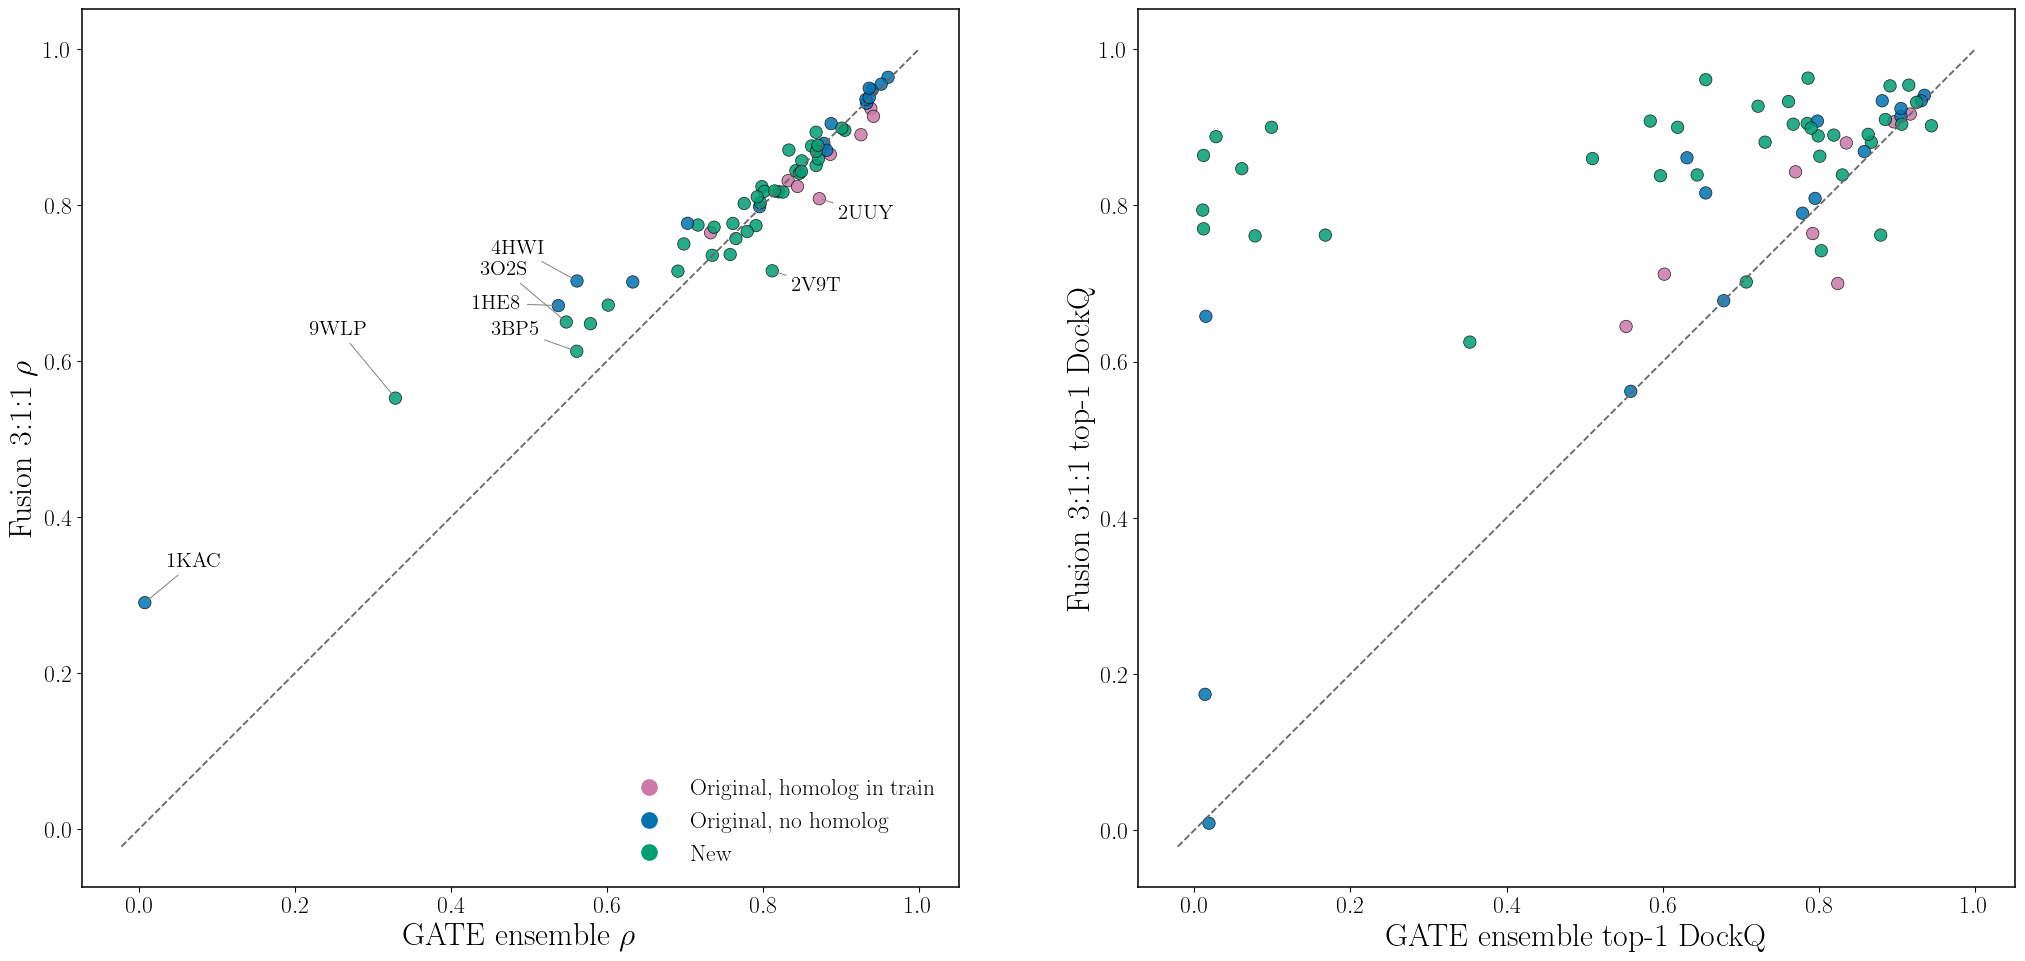

In [18]:
from scipy.stats import rankdata
WEIGHTS = {'GATE only': (1, 0, 0), '1:1:1': (1, 1, 1), '2:1:1': (2, 1, 1), '3:1:1': (3, 1, 1), '4:1:1': (4, 1, 1), '2:1:0': (2, 1, 0), '4:1:0': (4, 1, 0), '3:0:1': (3, 0, 1)}
def fusion(split):
    base = preds[CHOSEN, SEEDS[0]][split][['target_id', 'graph_name', 'true_target']].copy()
    base['GATE'] = np.mean([preds[CHOSEN, s][split].predicted_target.to_numpy() for s in SEEDS], axis=0)
    rows, dropped = [], []
    for t, g in base.groupby('target_id'):
        j = g.merge(score_table(t), left_on='graph_name', right_on='decoy', how='left')
        if j[CLASSICAL].isna().any(axis=1).mean() > .1:
            dropped.append(t); continue
        j = j[j[CLASSICAL].notna().all(axis=1)]
        y, names = j.true_target.to_numpy(), j.graph_name.to_numpy()
        rg, rz, rr = rankdata(j.GATE), rankdata(-j.ZRank2), rankdata(-j.Rosetta)
        for name, (a, b, c) in WEIGHTS.items():
            s = (a * rg + b * rz + c * rr) / (a + b + c)
            rows.append(dict(split=split, target=t, weights=name, rho=spearmanr(s, y).statistic, top1=top1(y, s, names)))
    return pd.DataFrame(rows), dropped
fus = {}; 
for split in ('validation', 'test'):
    fus[split], dropped = fusion(split); print(split, 'targets', fus[split].target.nunique(), 'dropped', dropped)
def fusion_table(r):
    p = r.pivot(index='target', columns='weights', values='rho'); b = p['GATE only']; names = list(WEIGHTS)
    t = r.groupby('weights')[['rho', 'top1']].mean().loc[names]
    t['worst'] = p.min().loc[names]; t['p10'] = p.quantile(.1).loc[names]
    t['helped'] = [int((p[c] > b + .02).sum()) for c in names]; t['harmed'] = [int((p[c] < b - .02).sum()) for c in names]
    t['largest_loss'] = [(p[c] - b).min() for c in names]
    return t
FT = {s: fusion_table(r) for s, r in fus.items()}
for s, t in FT.items():
    display(Markdown(f'**{s}**')); display(t.round(3)); t.to_csv(EXPORT / f'fusion_{s}.csv')
v = FT['validation']; ok = v[(v.harmed <= .15 * fus['validation'].target.nunique()) & (v.index != 'GATE only')]
FUSION = ok.rho.idxmax()
display(Markdown(f'**Chosen on validation: {FUSION}** (GATE : ZRank2 : Rosetta).'))
pt_ = fus['test'].pivot(index='target', columns='weights', values=['rho', 'top1'])
pt_.to_csv(EXPORT / 'fusion_test_per_target.csv')
e = {m: boot(pt_[(m, FUSION)] - pt_[(m, 'GATE only')]) for m in ('rho', 'top1')}
print(f"Test, paired vs GATE ensemble: delta rho {e['rho'][0]:+.3f} [{e['rho'][1]:+.3f}, {e['rho'][2]:+.3f}]; delta top-1 {e['top1'][0]:+.3f} [{e['top1'][1]:+.3f}, {e['top1'][2]:+.3f}]")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(21, 9.5), constrained_layout=True)
for ax, m, lab in ((a1, 'rho', r'$\rho$'), (a2, 'top1', 'top-1 DockQ')):
    x, y = pt_[(m, 'GATE only')], pt_[(m, FUSION)]
    lo = min(x.min(), y.min()) - .03
    ax.plot([lo, 1], [lo, 1], color='0.4', ls='--', lw=1.3)
    ax.scatter(x, y, s=80, color=[{'orig_homolog': '#CC79A7', 'orig_clean': '#0072B2', 'new': '#009E73'}[group_of(t)] for t in x.index], edgecolors='black', lw=.5, alpha=.85)
    ax.set_xlabel(f'GATE ensemble {lab}'); ax.set_ylabel(f'Fusion {FUSION} {lab}'); ax.set_aspect('equal', adjustable='box')
d_ = (pt_[('rho', FUSION)] - pt_[('rho', 'GATE only')]).sort_values()
# worst targets are labelled up and to the left (above the diagonal), the most harmed ones to the lower right
offs = [(16, 26), (-62, 46), (-62, 20), (-62, -2), (-62, 34), (-62, 12)]
for t, off in zip(BETTER[CHOSEN].sort_values().index[:6], offs):
    a1.annotate(t.upper(), (pt_.loc[t, ('rho', 'GATE only')], pt_.loc[t, ('rho', FUSION)]), xytext=off, textcoords='offset points', fontsize=15,
                arrowprops=dict(arrowstyle='-', color='0.5', lw=.7))
for t in d_.index[:2]:
    a1.annotate(t.upper(), (pt_.loc[t, ('rho', 'GATE only')], pt_.loc[t, ('rho', FUSION)]), xytext=(14, -14), textcoords='offset points', fontsize=15,
                arrowprops=dict(arrowstyle='-', color='0.5', lw=.7))
a1.legend(handles=[plt.Line2D([], [], marker='o', ls='none', ms=11, color=c, label=l) for l, c in (('Original, homolog in train', '#CC79A7'), ('Original, no homolog', '#0072B2'), ('New', '#009E73'))], frameon=False, loc='lower right')
save(fig, 'fusion_vs_gate_per_target')

## Why 1KAC fails

1KAC is the worst target for every GATE arm. It is the adenovirus knob bound to the D1 domain of its receptor CAR; the biological
assembly is a hetero 6-mer (three knobs, three CAR domains), and we dock one knob to one CAR. The isolated knob therefore exposes its
trimer-forming surface. Using the biological assembly (`inputs/1KAC.pdb1.gz`, from the RCSB) and the local 10\% subset of 1KAC decoys, this
section asks whether wrong poses land on that face, how many contacts they make, and what GATE predicts for them. It is one
target and a subset of its decoys: a mechanism for 1KAC, not a general claim.

Knob: 185 residues, trimer face 55 (30%), CAR contacts 19, overlap 3. Decoys in the local subset: 145.


,decoys,dockq,trimer_share,interface_edges,gate_prediction
cls,,,,,
acceptable,24,0.371,0.207,69.583,0.106
medium or better,46,0.733,0.150,82.152,0.117
"wrong, elsewhere",54,0.056,0.194,58.370,0.101
"wrong, on trimer face",21,0.026,0.795,80.238,0.185


rho(DockQ, interface edges): all 0.39; without wrong trimer-face poses 0.58
rho(DockQ, GATE prediction): all 0.06; without wrong trimer-face poses 0.29


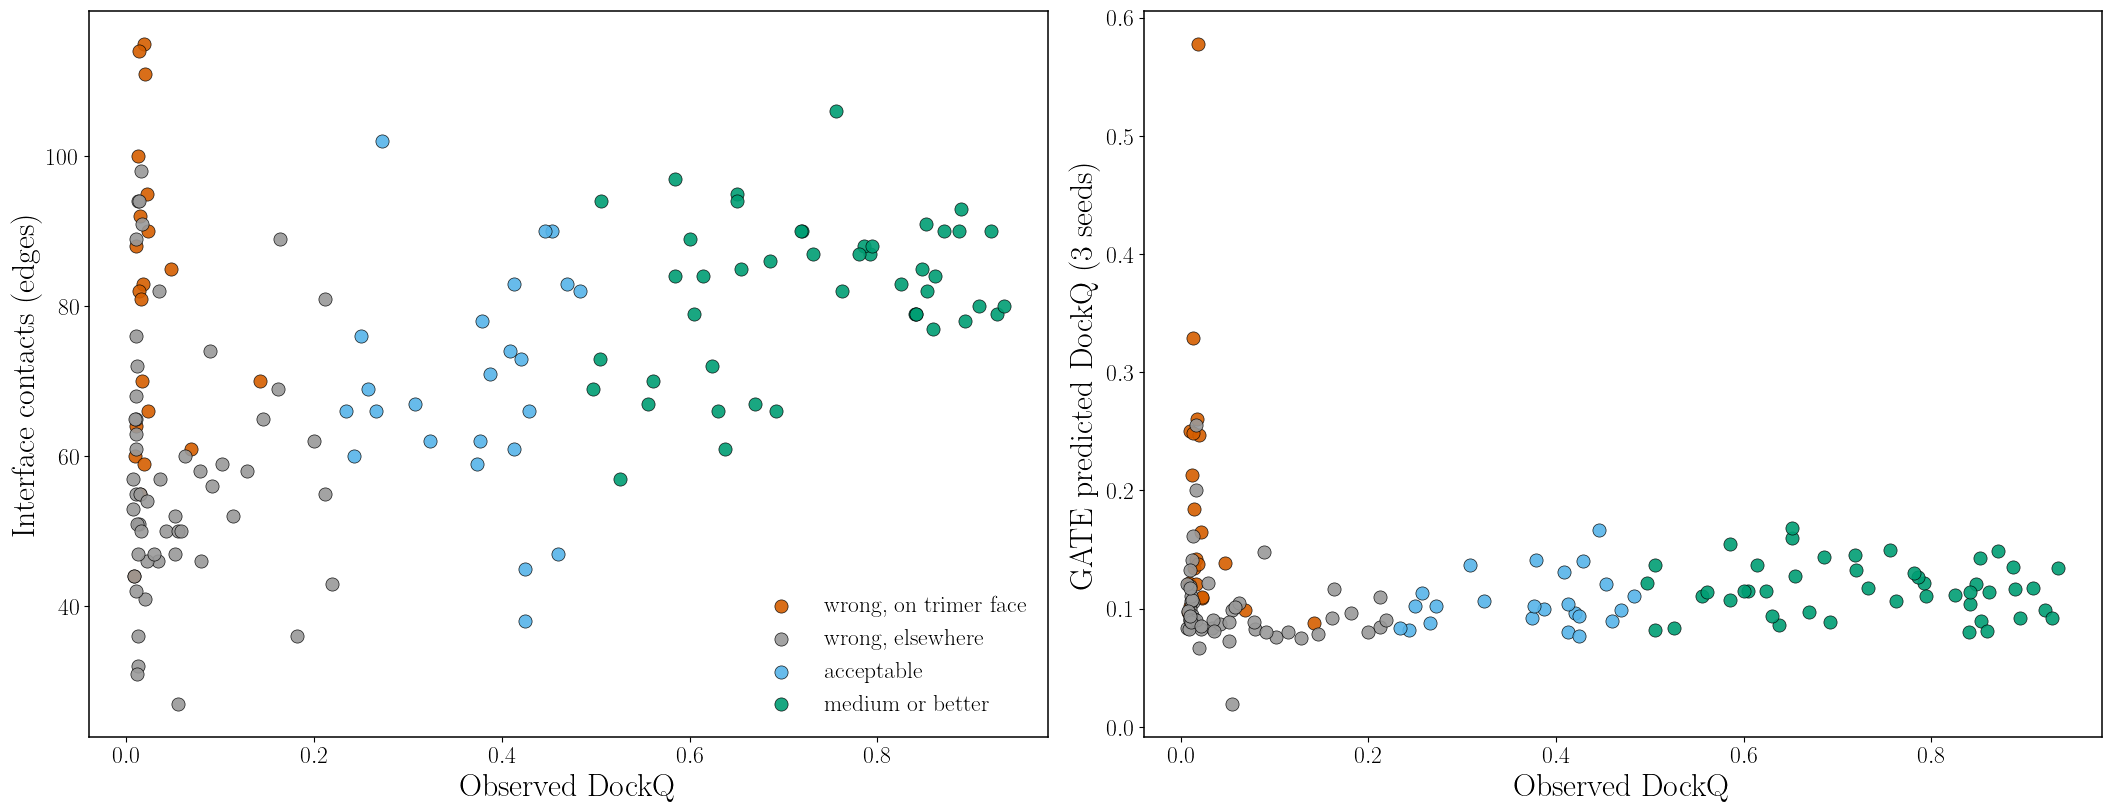

In [19]:
import gzip, difflib, h5py
from scipy.spatial import cKDTree
AA3 = {'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E','GLY':'G','HIS':'H','ILE':'I','LEU':'L','LYS':'K','MET':'M','PHE':'F','PRO':'P','SER':'S','THR':'T','TRP':'W','TYR':'Y','VAL':'V'}
rows, model = [], 1
for l in gzip.open(EXPORT / 'inputs' / '1KAC.pdb1.gz', 'rt'):
    if l.startswith('MODEL'): model = int(l.split()[1])
    if l.startswith('ATOM') and l[17:20] in AA3 and l[76:78].strip() != 'H' and l[16] in ' A':
        rows.append((model, l[21], int(l[22:26]), AA3[l[17:20]], float(l[30:38]), float(l[38:46]), float(l[46:54])))
asm = pd.DataFrame(rows, columns=['model', 'chain', 'res', 'aa', 'x', 'y', 'z'])
k1 = asm[(asm.model == 1) & (asm.chain == 'A')]; XYZ = ['x', 'y', 'z']
near = lambda other: set(k1.res[cKDTree(other[XYZ].to_numpy()).query(k1[XYZ].to_numpy())[0] < 5])
trimer = near(asm[(asm.model != 1) & (asm.chain == 'A')]); car = near(asm[(asm.model == 1) & (asm.chain == 'B')])
seq = k1.drop_duplicates('res').set_index('res').aa
h = h5py.File('/scratch/ppi_extension_data/full/subset_hdf5/1kac.hdf5', 'r')
pred = sum(preds[CHOSEN, s]['test'].query('target_id == "1kac"').set_index('graph_name').predicted_target for s in SEEDS) / len(SEEDS)
names = [n for n in h if n in pred.index]
nr = [[x.decode() if isinstance(x, bytes) else str(x) for x in r] for r in h[names[0]]['node_reference'][()]]
chain = np.array([r[1] for r in nr]); labels = sorted(set(chain), key=lambda c: -(chain == c).sum()); idx_k = np.where(chain == labels[0])[0]
gseq = ''.join(nr[i][2] for i in idx_k); pres = list(seq.index); mp = {}
for b in difflib.SequenceMatcher(None, gseq, ''.join(seq.values), autojunk=False).get_matching_blocks():
    for i in range(b.size): mp[int(idx_k[b.a + i])] = pres[b.b + i]
tri_nodes = {i for i, r in mp.items() if r in trimer}
rows = []
for n in names:
    g = h[n]; iface = np.asarray(g['node_features/interface_nodes'][()]).reshape(-1) != 0
    k = [i for i in idx_k if iface[i]]
    rows.append(dict(name=n, dockq=float(g['target_scores/DockQ'][()]), tri=np.mean([i in tri_nodes for i in k]) if k else 0,
                     edges=int((np.asarray(g['edge_features/interface_edges'][()]) != 0).sum()), pred=pred[n]))
kac = pd.DataFrame(rows); kac['cls'] = np.where(kac.dockq >= .49, 'medium or better', np.where(kac.dockq >= .23, 'acceptable', np.where(kac.tri >= .5, 'wrong, on trimer face', 'wrong, elsewhere')))
kac.to_csv(EXPORT / '1kac_decoys.csv', index=False)
print(f'Knob: {len(idx_k)} residues, trimer face {len(tri_nodes)} ({len(tri_nodes) / len(idx_k):.0%}), CAR contacts {len(car)}, overlap {len(trimer & car)}. Decoys in the local subset: {len(kac)}.')
display(kac.groupby('cls').agg(decoys=('dockq', 'size'), dockq=('dockq', 'mean'), trimer_share=('tri', 'mean'), interface_edges=('edges', 'mean'), gate_prediction=('pred', 'mean')).round(3))
excl = kac.cls != 'wrong, on trimer face'
print(f'rho(DockQ, interface edges): all {spearmanr(kac.dockq, kac.edges).statistic:.2f}; without wrong trimer-face poses {spearmanr(kac.dockq[excl], kac.edges[excl]).statistic:.2f}')
print(f'rho(DockQ, GATE prediction): all {spearmanr(kac.dockq, kac.pred).statistic:.2f}; without wrong trimer-face poses {spearmanr(kac.dockq[excl], kac.pred[excl]).statistic:.2f}')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(21, 8), constrained_layout=True)
CC = {'wrong, on trimer face': '#D55E00', 'wrong, elsewhere': '0.6', 'acceptable': '#56B4E9', 'medium or better': '#009E73'}
for c, col in CC.items():
    q = kac[kac.cls == c]
    a1.scatter(q.dockq, q.edges, s=90, color=col, edgecolors='black', lw=.5, label=c, alpha=.9)
    a2.scatter(q.dockq, q.pred, s=90, color=col, edgecolors='black', lw=.5, alpha=.9)
a1.set_xlabel('Observed DockQ'); a1.set_ylabel('Interface contacts (edges)'); a2.set_xlabel('Observed DockQ'); a2.set_ylabel('GATE predicted DockQ (3 seeds)')
a1.legend(frameon=False, loc='lower right')
save(fig, '1kac_trimer_face')

## Contact signal and hardness

Within each target, how well does the simple count of interface contacts follow DockQ? From the local 10\% subset (original test targets only:
graphs for the new targets are on the cluster). Targets where contacts are a weak signal are the hard ones, for ZRank2 and GATE alike. A
GATE value below the counting baseline means the model does worse than counting.

In [20]:
rows = []
for t in sorted(set(ref['test'].target_id) - new_targets):
    f = Path(f'/scratch/ppi_extension_data/full/subset_hdf5/{t}.hdf5')
    if not f.exists(): continue
    with h5py.File(f, 'r') as hf:
        d = np.array([(float(hf[n]['target_scores/DockQ'][()]), float((np.asarray(hf[n]['edge_features/interface_edges'][()]) != 0).sum())) for n in hf])
    rows.append(dict(target=t, group=TAG[group_of(t)], decoys=len(d), contact_rho=spearmanr(d[:, 0], d[:, 1]).statistic))
cs = pd.DataFrame(rows).set_index('target').join(BETTER[[CHOSEN, 'ZRank2', 'Rosetta']])
cs['gate_minus_counting'] = cs[CHOSEN] - cs.contact_rho; cs.to_csv(EXPORT / 'contact_signal.csv')
for m in (CHOSEN, 'ZRank2', 'Rosetta'):
    r_ = spearmanr(cs.contact_rho, cs[m]); print(f'contact signal vs {m} rho across {len(cs)} targets: r = {r_.statistic:+.2f} (p = {r_.pvalue:.1e})')
print(f"GATE better than counting contacts on {(cs.gate_minus_counting > 0).sum()} of {len(cs)} targets (mean difference {cs.gate_minus_counting.mean():+.3f}).")
display(cs.sort_values(CHOSEN).round(3))

contact signal vs rank0.3_8decoys rho across 23 targets: r = +0.76 (p = 2.8e-05)
contact signal vs ZRank2 rho across 23 targets: r = +0.90 (p = 3.7e-09)
contact signal vs Rosetta rho across 23 targets: r = +0.48 (p = 2.0e-02)
GATE better than counting contacts on 19 of 23 targets (mean difference +0.157).


,group,decoys,contact_rho,rank0.3_8decoys,ZRank2,Rosetta,gate_minus_counting
target,,,,,,,
1kac,O,145,0.395,0.013,0.612,0.520,-0.381
4hwi,O,98,0.228,0.445,0.755,0.720,0.217
1he8,O,96,0.459,0.498,0.720,0.461,0.040
1j2j,O,126,0.410,0.610,0.621,0.690,0.200
1z5y,O,113,0.260,0.679,0.632,0.687,0.419
4k12,H,135,0.701,0.712,0.679,0.671,0.011
3fpn,O,134,0.871,0.759,0.814,0.334,-0.112
1acb,H,135,0.216,0.822,0.624,0.755,0.606
1oph,H,111,0.164,0.826,0.438,0.695,0.662


## Every test target: control vs the arm chosen on validation

Both arms in each panel, each at its lowest-validation-MSE seed; the annotation gives the target, its group and each
arm's $\rho$.

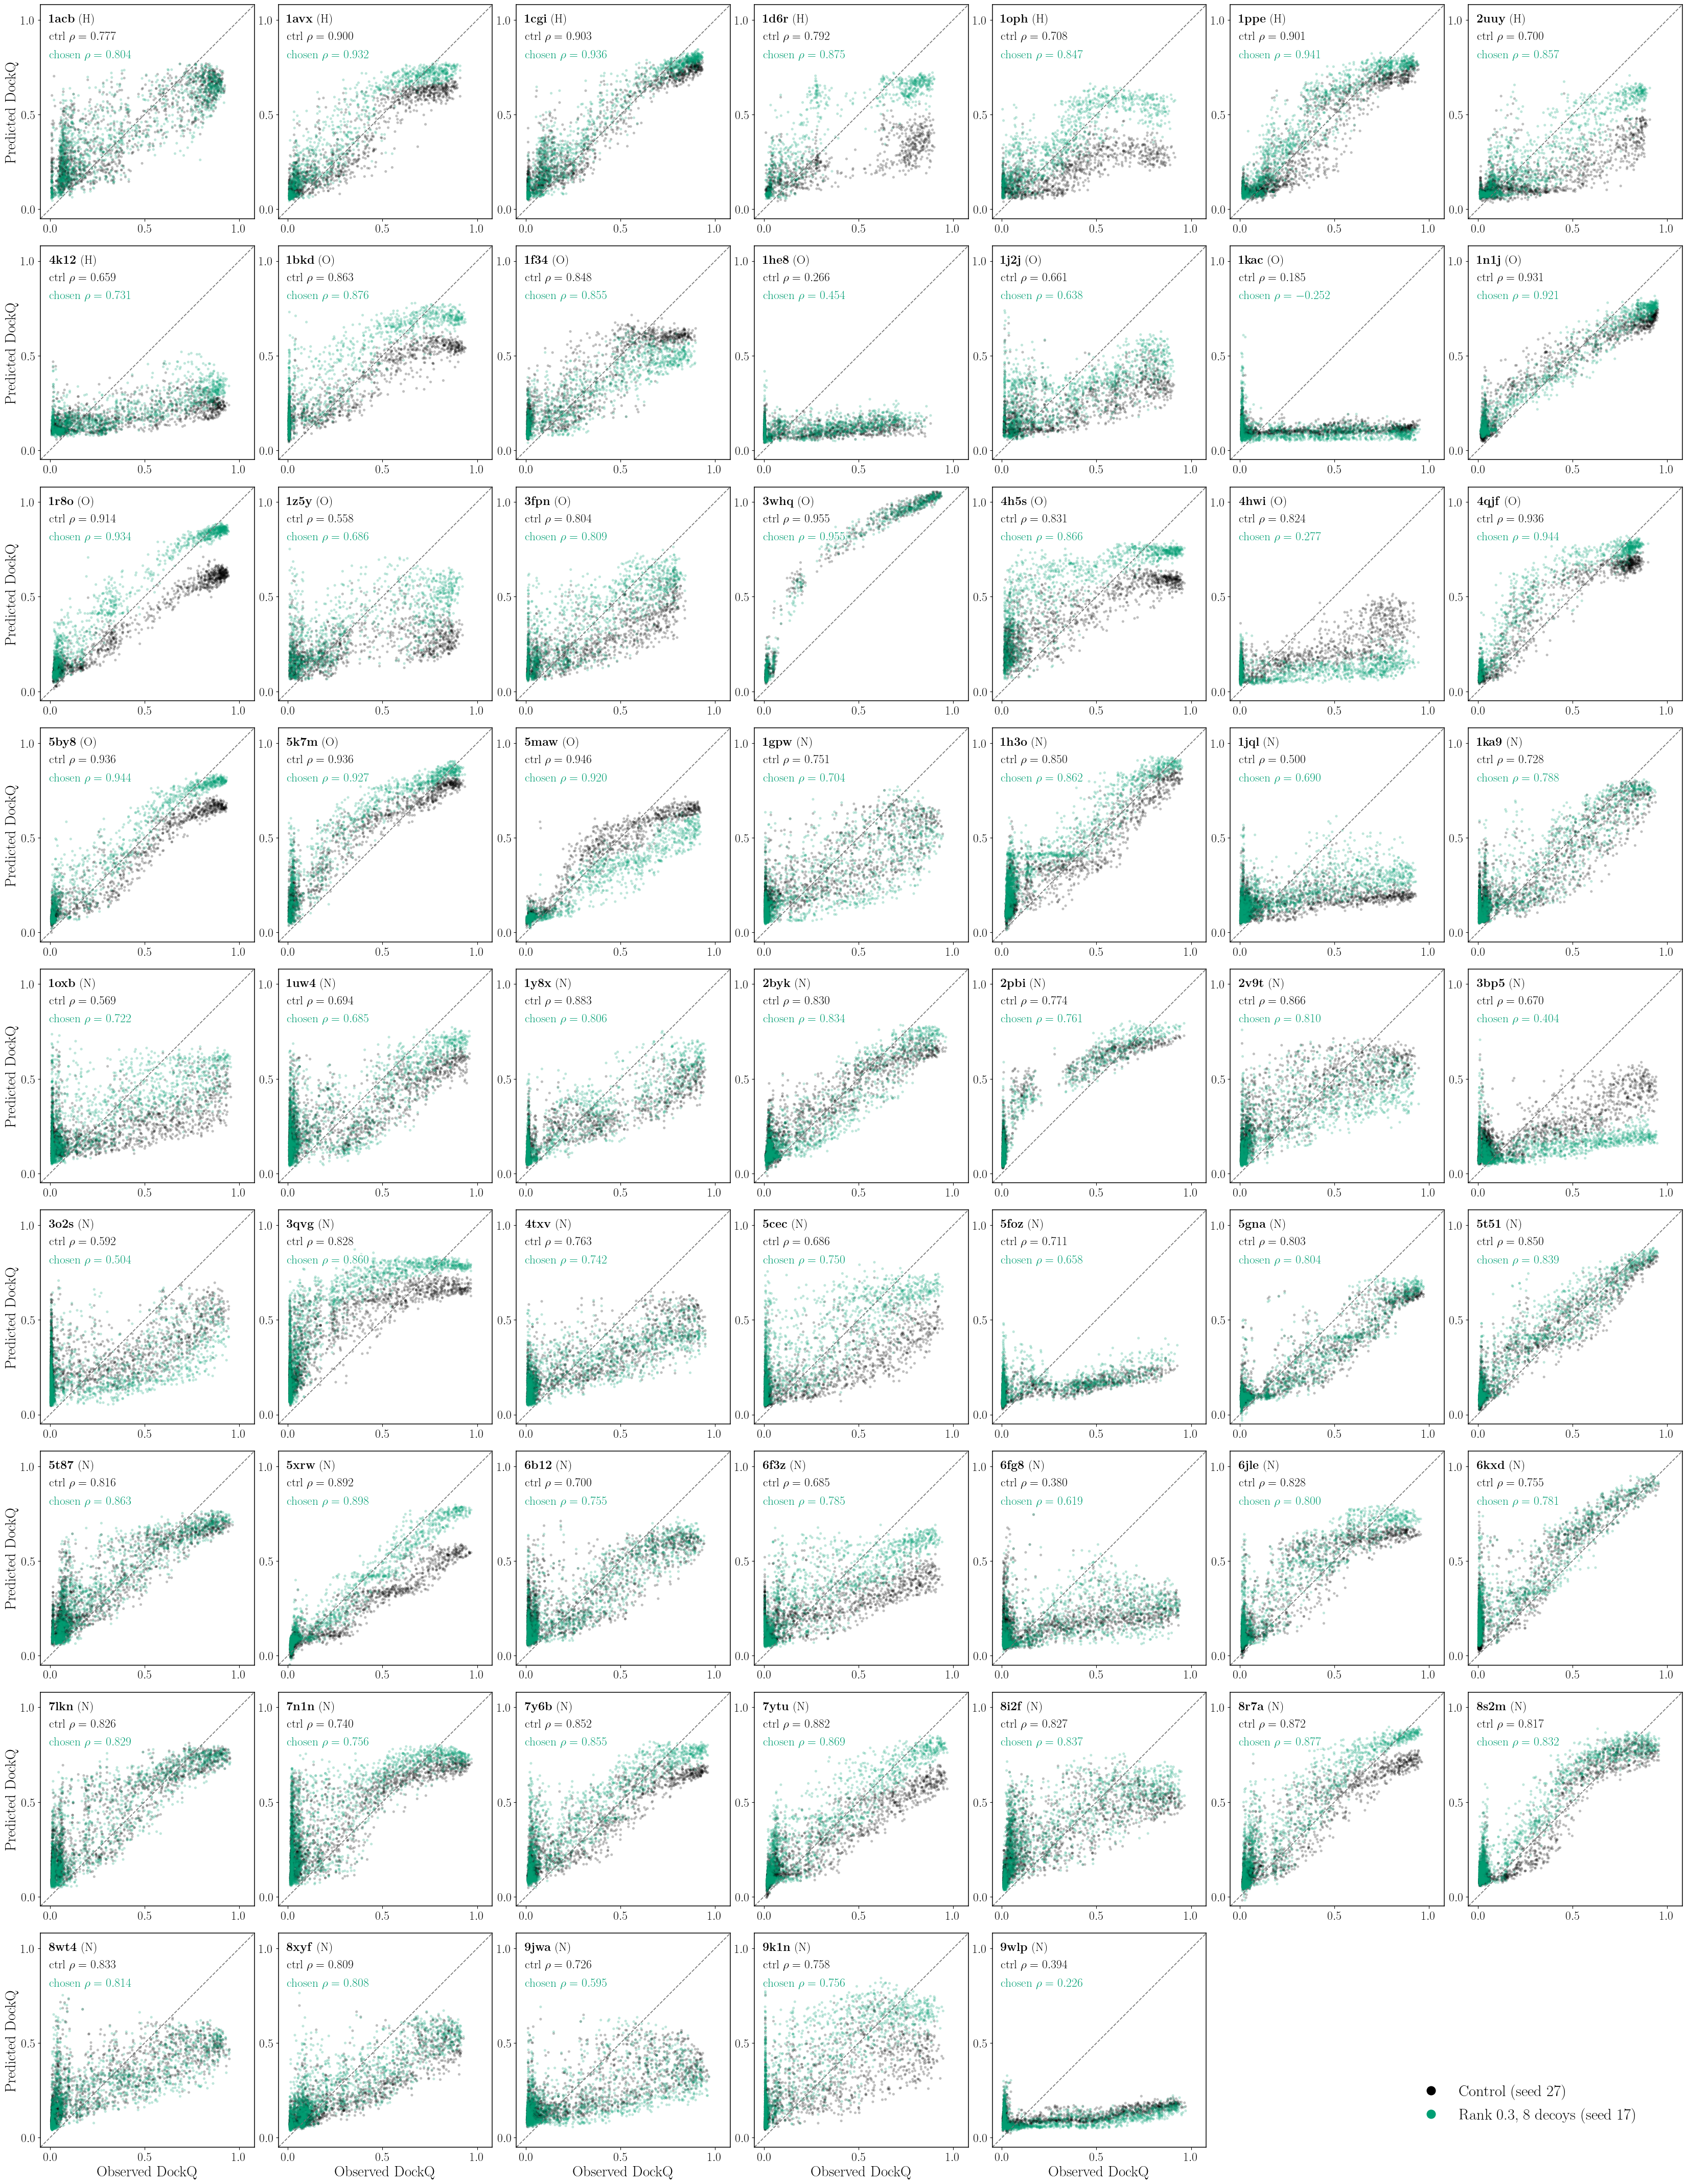

In [21]:
lim = (-.05, 1.08)
val_seed = {a: int(metrics[(metrics.split == 'validation') & (metrics.group == 'all') & (metrics.arm == a)].set_index('seed').mse.idxmin()) for a in ARMS}
targets = sorted(ref['test'].target_id.unique(), key=lambda t: (GROUPS.index(group_of(t)), t)); ncols = 7; nrows = int(np.ceil(len(targets) / ncols))
arms_ = ['control', CHOSEN if CHOSEN != 'control' else 'rank0.3']; short = {'control': 'ctrl', arms_[1]: 'chosen'}
with mpl.rc_context({'axes.labelsize': 21, 'xtick.labelsize': 17, 'ytick.labelsize': 17}):
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.7 * ncols, 4.75 * nrows), sharex=True, sharey=True, constrained_layout=True)
    for ax, t in zip(axes.flat, targets):
        ax.text(.04, .96, rf'\textbf{{{t}}} ({TAG[group_of(t)]})', transform=ax.transAxes, va='top', fontsize=17, bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1.5))
        for k, a in enumerate(arms_):
            d = preds[a, val_seed[a]]['test']; g = d[d.target_id == t]
            ax.scatter(g.true_target, g.predicted_target.clip(*lim), color=COLOR[a], alpha=.25, s=14, edgecolors='none', rasterized=True)
            ax.text(.04, .96 - .085 * (k + 1), rf'{short[a]} $\rho = {spearmanr(g.true_target, g.predicted_target).statistic:.3f}$', transform=ax.transAxes, va='top',
                    fontsize=17, color=COLOR[a], bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1.5))
        ax.plot(lim, lim, color='0.45', ls='--', lw=1.2); ax.set(xlim=lim, ylim=lim, xticks=[0, .5, 1], yticks=[0, .5, 1]); ax.set_aspect('equal', adjustable='box')
        ax.tick_params(labelbottom=True, labelleft=True)
    for ax in axes[-1]: ax.set_xlabel('Observed DockQ')
    for ax in axes[:, 0]: ax.set_ylabel('Predicted DockQ')
    for ax in list(axes.flat)[len(targets):]: ax.set_visible(False)
    fig.legend(handles=[plt.Line2D([], [], marker='o', ls='none', ms=12, color=COLOR[a], label=f'{LABEL[a]} (seed {val_seed[a]})') for a in arms_],
               loc='lower right', bbox_to_anchor=(.98, .02), frameon=False, fontsize=22)
    save(fig, 'test_per_target_control_vs_chosen', dpi=120)

## Readout

In [22]:
def ms(split, grp, arm, col, f='.4f'):
    return f"{agg.loc[(split, grp, arm), (col, 'mean')]:{f}} ± {agg.loc[(split, grp, arm), (col, 'std')]:{f}}"
lines = [f'Chosen on validation: **{LABEL[CHOSEN]}**. Seed mean ± SD.', '',
         '| arm | val MSE | val ⟨ρ⟩ | val top-1 | test MSE | test ⟨ρ⟩ | ρ H | ρ O | ρ N | test top-1 | epoch |', '|---|---|---|---|---|---|---|---|---|---|---|']
for a in ARMS + REFS:
    lines.append(f"| {LABEL[a]} | {ms('validation', 'all', a, 'mse')} | {ms('validation', 'all', a, 'macro_rho', '.3f')} | {ms('validation', 'all', a, 'top1', '.3f')} | "
                 f"{ms('test', 'all', a, 'mse')} | {ms('test', 'all', a, 'macro_rho', '.3f')} | {ms('test', 'orig_homolog', a, 'macro_rho', '.3f')} | "
                 f"{ms('test', 'orig_clean', a, 'macro_rho', '.3f')} | {ms('test', 'new', a, 'macro_rho', '.3f')} | {ms('test', 'all', a, 'top1', '.3f')} | {ms('test', 'all', a, 'best_epoch', '.1f')} |")
lines += ['', 'Paired vs control, 95% bootstrap CI over targets (positive favours the arm):']
for a in ARMS[1:]:
    for split in ('validation', 'test'):
        r = eff[(eff.arm == a) & (eff.split == split) & (eff.group == 'all')].set_index('metric')
        lines.append(f"- {LABEL[a]}, {split}: Δρ {r.loc['drho', 'mean']:+.3f} [{r.loc['drho', 'lo']:+.3f}, {r.loc['drho', 'hi']:+.3f}]; "
                     f"−ΔMSE {r.loc['dmse', 'mean']:+.4f} [{r.loc['dmse', 'lo']:+.4f}, {r.loc['dmse', 'hi']:+.4f}]; Δtop-1 {r.loc['dtop1', 'mean']:+.3f} [{r.loc['dtop1', 'lo']:+.3f}, {r.loc['dtop1', 'hi']:+.3f}]")
text = '\n'.join(lines); display(Markdown(text)); _ = (EXPORT / 'readout.md').write_text(text)

Chosen on validation: **Rank 0.3, 8 decoys**. Seed mean ± SD.

| arm | val MSE | val ⟨ρ⟩ | val top-1 | test MSE | test ⟨ρ⟩ | ρ H | ρ O | ρ N | test top-1 | epoch |
|---|---|---|---|---|---|---|---|---|---|---|
| Control | 0.0435 ± 0.0022 | 0.701 ± 0.013 | 0.591 ± 0.024 | 0.0383 ± 0.0002 | 0.762 ± 0.007 | 0.819 ± 0.024 | 0.765 ± 0.022 | 0.748 ± 0.005 | 0.581 ± 0.012 | 5.0 ± 1.7 |
| Rank 0.3 | 0.0424 ± 0.0013 | 0.706 ± 0.009 | 0.590 ± 0.018 | 0.0375 ± 0.0012 | 0.762 ± 0.008 | 0.858 ± 0.005 | 0.742 ± 0.042 | 0.750 ± 0.005 | 0.603 ± 0.018 | 8.0 ± 1.0 |
| Rank 1.0 | 0.0432 ± 0.0004 | 0.712 ± 0.006 | 0.586 ± 0.009 | 0.0364 ± 0.0003 | 0.775 ± 0.003 | 0.866 ± 0.015 | 0.767 ± 0.007 | 0.759 ± 0.001 | 0.627 ± 0.008 | 6.3 ± 0.6 |
| Rank 0.3, 8 decoys | 0.0427 ± 0.0002 | 0.713 ± 0.019 | 0.596 ± 0.022 | 0.0372 ± 0.0011 | 0.772 ± 0.011 | 0.860 ± 0.006 | 0.761 ± 0.029 | 0.758 ± 0.006 | 0.605 ± 0.014 | 8.0 ± 1.7 |
| Interface pooling | 0.0450 ± 0.0017 | 0.712 ± 0.001 | 0.553 ± 0.031 | 0.0372 ± 0.0025 | 0.742 ± 0.014 | 0.809 ± 0.026 | 0.769 ± 0.028 | 0.716 ± 0.011 | 0.609 ± 0.040 | 4.0 ± 2.0 |
| Expanded, 20 ep | 0.0434 ± 0.0010 | 0.716 ± 0.008 | 0.581 ± 0.055 | 0.0397 ± 0.0011 | 0.760 ± 0.007 | 0.844 ± 0.020 | 0.750 ± 0.013 | 0.746 ± 0.002 | 0.599 ± 0.002 | 7.7 ± 4.0 |
| Original only, 20 ep | 0.0494 ± 0.0005 | 0.705 ± 0.013 | 0.570 ± 0.027 | 0.0473 ± 0.0012 | 0.707 ± 0.003 | 0.639 ± 0.025 | 0.727 ± 0.005 | 0.712 ± 0.007 | 0.538 ± 0.010 | 11.0 ± 4.6 |
| Wide, 20 ep | 0.0485 ± 0.0012 | 0.695 ± 0.008 | 0.564 ± 0.017 | 0.0426 ± 0.0037 | 0.735 ± 0.003 | 0.844 ± 0.019 | 0.748 ± 0.009 | 0.707 ± 0.012 | 0.553 ± 0.050 | 2.7 ± 2.1 |

Paired vs control, 95% bootstrap CI over targets (positive favours the arm):
- Rank 0.3, validation: Δρ +0.005 [-0.028, +0.028]; −ΔMSE +0.0015 [-0.0005, +0.0038]; Δtop-1 -0.001 [-0.049, +0.040]
- Rank 0.3, test: Δρ +0.001 [-0.019, +0.017]; −ΔMSE +0.0009 [-0.0013, +0.0032]; Δtop-1 +0.022 [-0.014, +0.060]
- Rank 1.0, validation: Δρ +0.011 [-0.016, +0.033]; −ΔMSE +0.0006 [-0.0021, +0.0032]; Δtop-1 -0.005 [-0.045, +0.036]
- Rank 1.0, test: Δρ +0.014 [-0.005, +0.031]; −ΔMSE +0.0019 [-0.0008, +0.0045]; Δtop-1 +0.045 [+0.006, +0.083]
- Rank 0.3, 8 decoys, validation: Δρ +0.013 [-0.003, +0.029]; −ΔMSE +0.0012 [-0.0005, +0.0030]; Δtop-1 +0.005 [-0.045, +0.053]
- Rank 0.3, 8 decoys, test: Δρ +0.010 [-0.003, +0.025]; −ΔMSE +0.0013 [-0.0007, +0.0033]; Δtop-1 +0.023 [-0.006, +0.055]
- Interface pooling, validation: Δρ +0.011 [-0.016, +0.051]; −ΔMSE -0.0011 [-0.0043, +0.0022]; Δtop-1 -0.038 [-0.081, +0.001]
- Interface pooling, test: Δρ -0.020 [-0.035, -0.004]; −ΔMSE +0.0010 [-0.0015, +0.0038]; Δtop-1 +0.027 [-0.010, +0.066]

## Interpretation

Written from the final results of all fifteen sweep runs (2 November 2026).

**The chosen arm is rank 0.3 with 8 decoys per target, but the gain is small.** It ranks first on validation
$\langle\rho\rangle$ and top-1 and second on MSE. Paired against the control it improves $\langle\rho\rangle$ by 0.013 on
validation [$-0.003$, $+0.029$] and by 0.010 on test [$-0.003$, $+0.025$]: the same direction and size on both, but both
intervals include zero, and the seed spreads are as large as the differences between the top arms. The honest
summary is that the ranking-loss arms are slightly better than the control and hard to separate from each other.

**Rank 1.0 has the best test numbers, but they did not appear on validation.** Test $\langle\rho\rangle$ 0.775 and
top-1 0.627 (+0.045 vs control, interval excludes zero) against a validation top-1 change of $-0.005$. Picking it because
of its test numbers would be selecting on test. It is a good candidate to carry alongside the chosen arm to the next fold.

**A stronger ranking signal did what it was designed to do, modestly.** Within-target error fell from 0.0318 (control) to
0.0292 (rank 1.0), the within-target slope rose from 0.55 to 0.60, and flat targets fell from 6 to about 4. Most of the
test error is still within targets, and the gap between training (0.024) and validation (0.043) DockQ MSE is unchanged:
the limit is still generalization to unseen targets.

**Interface pooling confirmed the mechanism but is not an improvement overall.** The evidence for the hypothesis: the
correlation between a target's offset and its interface share fell from $+0.47$ to $+0.28$, flat targets fell from 6 to
about 3, the four collapsed targets improved on average ($\rho$ 0.37 to 0.44, 4hwi 0.52 to 0.76), and their offset shrank.
But it does not rescue 1kac or 1he8, and it costs ranking elsewhere: test $\langle\rho\rangle$ $-0.020$ [$-0.035$,
$-0.004$], mainly on new targets (0.748 to 0.716), with worse validation MSE and top-1. The whole-graph summary hurts a
few targets and helps many, so combined pooling stays.

**Ten epochs lose nothing.** The 10-epoch control matches the 20-epoch expanded runs (test MSE 0.0383 vs 0.0397,
$\langle\rho\rangle$ 0.762 vs 0.760) at half the cost, so 10 epochs should be the default.

**Averaging seeds helps at least as much as any hyperparameter tested here.** Averaging the three seeds' predictions improves
$\langle\rho\rangle$ by 0.01--0.02 and MSE by about 0.002, on both validation and test and in every arm (top-1 changes are mixed). That is
at least as large as any arm's effect and needs no extra runs. The chosen arm's ensemble reaches test MSE 0.0353 and
$\langle\rho\rangle$ 0.787 (validation 0.0409 and 0.726).

**Against the classical functions.** The chosen arm's $\langle\rho\rangle_t$ of $-0.772$ is ahead of ZRank2 ($-0.746$), PyDock
($-0.646$) and Rosetta ($-0.423$), and it is best or within 0.02 of the best on 39 of 61 targets (control 38,
20-epoch expanded 34). Rosetta still picks the single best decoy far better (top-1 0.82 vs 0.61).

**The hard targets.** In the hardest quartile for the classical functions (16 targets) the chosen arm averages
$\rho = -0.69$ against ZRank2 $-0.62$, PyDock $-0.32$ and Rosetta $-0.17$. Part of that is homolog leakage: without the
3 homolog targets it is $-0.66$ vs $-0.64$, about even. On the 11 new targets in that quartile the lead is clearer ($-0.73$ vs
$-0.64$, ahead on 10). The exceptions are where GATE fails: 1KAC, 1HE8 and 3BP5.

**The worst target is 1KAC, for every GATE arm.** $\rho \approx 0$ and unstable across seeds ($+0.04$, $-0.25$, $+0.25$), while
ZRank2 reaches $-0.61$ and Rosetta $-0.52$. Counting contacts alone gives 0.39, so GATE is worse than counting here (and only here by
a wide margin; it beats counting on 19 of 23 original targets). The likely cause is specific: the knob is an obligate trimer docked as a
monomer, so its trimer face (30\% of its surface) is exposed. Of 75 wrong poses in the local subset, 21 sit mostly on that face, with
as many contacts as the good poses (80 vs 82, other wrong poses 58), and GATE predicts them **higher** (0.185) than the medium-or-better
poses (0.117). Without them, its $\rho$ on this subset rises from 0.06 to 0.29 and the contact signal from 0.39 to 0.58. This fits better than
the interface-share explanation, since interface pooling did not rescue 1KAC. Other multimers in the test set (1BKD, 1D6R) are fine,
so this is not a general rule about oligomers.

**Improving the worst targets without hurting the others.** The classical functions fail on different targets than GATE, so
combining them works. With weights chosen on validation (3:1:1, GATE ensemble : ZRank2 : Rosetta), against the GATE ensemble on test:
$\langle\rho\rangle$ 0.787 to 0.807 ($+0.021$ [$+0.007$, $+0.036$]), worst target 0.01 to 0.29, 10th percentile 0.58 to 0.67, and top-1 0.64 to
0.82 ($+0.18$ [$+0.12$, $+0.25$]), matching Rosetta alone. 19 targets gain more than 0.02 and 7 lose more than 0.02, the largest loss
0.096 (2V9T). Validation agrees ($\langle\rho\rangle$ 0.723 to 0.751, worst $-0.40$ to 0.02, top-1 0.61 to 0.74, 4 targets harmed). Costs: it needs
ZRank2 and Rosetta scores for every decoy, it gives an ordering rather than a DockQ value, and the top-1 gain comes mostly from Rosetta.

**Head-to-head with ZRank2.** GATE wins more targets, but its mean advantage is not secure. Over all 61 targets $\langle\rho\rangle$ is $-0.772$ vs
$-0.746$ ($\Delta = +0.026$ [$-0.017$, $+0.067$]); by target it wins 30 and loses 10 at a margin above 0.02 (sign test $p = 0.002$, Wilcoxon
$p = 0.007$). All three seeds agree in direction. Much of the mean comes from the 8 homolog targets, where it wins 8 of 8 ($\Delta = +0.20$): with
those removed the mean difference is zero ($-0.759$ for both), although GATE still wins 22 and loses 10 (sign test $p = 0.05$, median $\Delta = +0.009$). The pattern is
many small wins against a few large losses: 1KAC, 9WLP, 4HWI, 3O2S and 1HE8 cost more than the small wins return. On the 37 new targets GATE wins 19 to 6
($p = 0.015$, $\Delta = +0.025$ [$-0.018$, $+0.072$]). On the 16 clean original targets ZRank2 is ahead ($\Delta = -0.057$ [$-0.151$, $+0.014$]). The 3-seed ensemble
is stronger: 33 to 9 overall and 25 to 9 on clean targets ($p = 0.009$), $\Delta = +0.041$ [$-0.000$, $+0.082$] and $+0.015$ [$-0.027$, $+0.055$]. Top-1 is level
(0.605 vs 0.593 overall, 0.587 vs 0.624 clean). A defensible statement: GATE outranks ZRank2 on more targets, including most new targets, and is at least level on
average, but it does not yet have a significantly better mean on targets without homologs. These test targets have also been read repeatedly.

**Limitations.** One fold and three seeds. This test set has now been read several times, so these test values are
optimistic and not a final estimate. The H group still includes homolog leakage. Confirming the choice needs a
fold with an unread test set.